<a href="https://colab.research.google.com/github/SharuNivetha06/AttentionMechanism/blob/main/notebook0774737492.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install --no-cache-dir "protobuf==6.33.6"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 16.1 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import sys
import google.protobuf

print("Python:", sys.executable)
print("Protobuf version:", google.protobuf.__version__)
print("Protobuf location:", google.protobuf.__file__)

Python: /usr/bin/python3
Protobuf version: 6.33.6
Protobuf location: /usr/local/lib/python3.13/dist-packages/google/protobuf/__init__.py


In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)
print("TFDS imported successfully!")
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
TFDS imported successfully!
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
import os, time, random, json, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.model_selection import ParameterGrid

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 224
NUM_CLASSES = 5
BATCH_SIZE = 32
EPOCHS_TUNING = 5       # Increase (e.g. 8-15) for a more reliable tuning run.
EPOCHS_ATTENTION = 8    # Keep identical for all attention comparisons.
FINE_TUNE_EPOCHS = 0    # Optional; see fine-tuning note below.

TensorFlow: 2.20.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
(ds_all, ds_info) = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)
class_names = ds_info.features["label"].names
print("Classes:", class_names, "| Total examples:", ds_info.splits["train"].num_examples)

examples = list(tfds.as_numpy(ds_all))
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(examples))
n = len(indices)
n_train, n_val = int(0.70*n), int(0.15*n)
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train+n_val]
test_idx = indices[n_train+n_val:]

def make_arrays(idxs):
    xs, ys = [], []
    for i in idxs:
        image, label = examples[int(i)]
        xs.append(tf.image.resize(image, (IMG_SIZE, IMG_SIZE)).numpy().astype("float32"))
        ys.append(int(label))
    return np.stack(xs), np.asarray(ys, dtype="int32")

x_train, y_train = make_arrays(train_idx)
x_val, y_val = make_arrays(val_idx)
x_test, y_test = make_arrays(test_idx)
print("Train:", x_train.shape, "Validation:", x_val.shape, "Test:", x_test.shape)
print("Class counts (train):", dict(zip(class_names, np.bincount(y_train, minlength=NUM_CLASSES))))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.


I0000 00:00:1792477818.770210      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792477818.773442      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses'] | Total examples: 3670
Train: (2569, 224, 224, 3) Validation: (550, 224, 224, 3) Test: (551, 224, 224, 3)
Class counts (train): {'dandelion': np.int64(609), 'daisy': np.int64(464), 'tulips': np.int64(549), 'sunflowers': np.int64(506), 'roses': np.int64(441)}


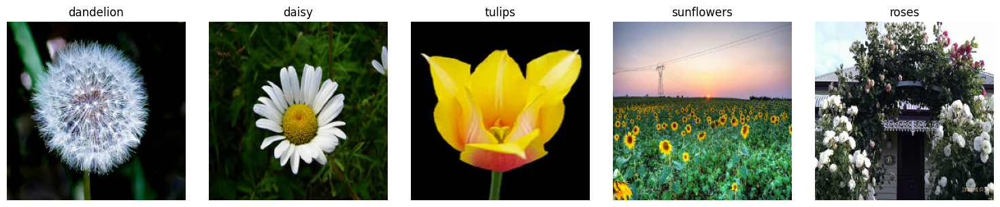

In [ ]:
# Preview samples from all five classes
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 3))
for c, ax in enumerate(axes):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(x_train[idx].astype("uint8"))
    ax.set_title(class_names[c])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal", seed=SEED),
    tf.keras.layers.RandomRotation(0.05, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomTranslation(0.05, 0.05, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name="shared_augmentation")

def prepare_train(image, label):
    image = data_augmentation(image, training=True)
    image = preprocess_input(image)
    return image, tf.one_hot(label, NUM_CLASSES)

def prepare_eval(image, label):
    image = preprocess_input(image)
    return image, tf.one_hot(label, NUM_CLASSES)

def make_dataset(x, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(prepare_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(prepare_eval, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, training=True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)

In [ ]:
from tensorflow.keras import layers, Model

STAGE_LAYER = {
    "P1": "conv2_block3_out",
    "P2": "conv3_block4_out",
    "P3": "conv4_block6_out",
    "P4": "conv5_block3_out",
}
STAGE_SHAPES = {"P1": (56,56,256), "P2": (28,28,512), "P3": (14,14,1024), "P4": (7,7,2048)}

def build_stage_model(stage="P3", attention="none", dropout=0.4, reduction=16,
                      spatial_kernel=7, attention_order="channel_spatial",
                      multi_stages=None, pretrained=True):
    """Build ResNet50 with an attention block after selected stage output(s).
    Uses nested stage submodels so pretrained convolution weights are reused.
    """
    weights = "imagenet" if pretrained else None
    backbone = tf.keras.applications.ResNet50(
        include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    backbone.trainable = False
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = inputs
    stages = ["P1", "P2", "P3", "P4"]
    selected = multi_stages if multi_stages is not None else ([stage] if stage else [])
    prev_tensor = backbone.input
    # Build a submodel from backbone input through each stage, then chain the stage segments.
    start_layer_index = 0
    for p in stages:
        end_layer_index = backbone.get_layer(STAGE_LAYER[p])._inbound_nodes[0].output_tensors
        end_tensor = backbone.get_layer(STAGE_LAYER[p]).output
        segment = Model(inputs=prev_tensor, outputs=end_tensor, name=f"segment_{p}")
        x = segment(x)
        if p in selected:
            x = apply_attention(x, attention, reduction, spatial_kernel, attention_order, name=f"{attention}_{p}")
        prev_tensor = end_tensor
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="classifier_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    model = Model(inputs, outputs, name=f"ResNet50_{attention}_{stage or 'multi'}")
    return model, backbone

def channel_attention(x, reduction=16, name="channel_attention"):
    channels = int(x.shape[-1])
    hidden = max(channels // reduction, 8)
    avg = layers.GlobalAveragePooling2D(keepdims=True, name=f"{name}_gap")(x)
    shared1 = layers.Dense(hidden, activation="relu", use_bias=True, name=f"{name}_fc1")
    shared2 = layers.Dense(channels, activation="sigmoid", use_bias=True, name=f"{name}_fc2")
    scale = shared2(shared1(avg))
    return layers.Multiply(name=f"{name}_scale")([x, scale])

def spatial_attention(x, kernel_size=7, name="spatial_attention"):
    avg = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                        name=f"{name}_avg_pool")(x)
    mx = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                       name=f"{name}_max_pool")(x)
    pooled = layers.Concatenate(axis=-1, name=f"{name}_pool_concat")([avg, mx])
    mask = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid",
                         use_bias=False, name=f"{name}_conv")(pooled)
    return layers.Multiply(name=f"{name}_scale")([x, mask])

def se_attention(x, reduction=16, name="se"):
    return channel_attention(x, reduction=reduction, name=name)

def eca_attention(x, name="eca"):
    channels = int(x.shape[-1])
    avg = layers.GlobalAveragePooling2D(keepdims=True)(x)  # (B,1,1,C)
    # 1D convolution across channel dimension; reshape channel descriptor to (B,C,1).
    z = layers.Reshape((channels, 1), name=f"{name}_reshape_in")(avg)
    k = int(abs((np.log2(channels) / 2) + 0.5))
    k = max(3, k if k % 2 else k + 1)
    z = layers.Conv1D(1, kernel_size=k, padding="same", use_bias=False, name=f"{name}_conv1d")(z)
    z = layers.Activation("sigmoid", name=f"{name}_sigmoid")(z)
    z = layers.Reshape((1, 1, channels), name=f"{name}_reshape_out")(z)
    return layers.Multiply(name=f"{name}_scale")([x, z])

def cbam_attention(x, reduction=16, kernel_size=7, name="cbam"):
    # Shared MLP is applied to average- and max-pooled channel descriptors.
    channels = int(x.shape[-1]); hidden = max(channels // reduction, 8)
    avg = layers.GlobalAveragePooling2D(keepdims=True)(x)
    mx = layers.GlobalMaxPooling2D(keepdims=True)(x)
    fc1 = layers.Dense(hidden, activation="relu", name=f"{name}_fc1")
    fc2 = layers.Dense(channels, name=f"{name}_fc2")
    c = layers.Activation("sigmoid")(layers.Add()([fc2(fc1(avg)), fc2(fc1(mx))]))
    x = layers.Multiply(name=f"{name}_channel_scale")([x, c])
    return spatial_attention(x, kernel_size, name=f"{name}_spatial")

def coordinate_attention(x, reduction=16, name="coord"):
    # Lightweight coordinate attention: encode height and width separately.
    h, w, c = int(x.shape[1]), int(x.shape[2]), int(x.shape[-1])
    x_h = layers.Lambda(lambda t: tf.reduce_mean(t, axis=2, keepdims=True), name=f"{name}_pool_h")(x) # B,H,1,C
    x_w = layers.Lambda(lambda t: tf.reduce_mean(t, axis=1, keepdims=True), name=f"{name}_pool_w")(x) # B,1,W,C
    x_w = layers.Permute((2, 1, 3), name=f"{name}_permute_w")(x_w) # B,W,1,C
    y = layers.Concatenate(axis=1, name=f"{name}_concat")([x_h, x_w])
    hidden = max(8, c // reduction)
    y = layers.Conv2D(hidden, 1, activation="relu", name=f"{name}_conv1")(y)
    y_h = layers.Lambda(lambda t: t[:, :h, :, :], name=f"{name}_split_h")(y)
    y_w = layers.Lambda(lambda t: t[:, h:, :, :], name=f"{name}_split_w")(y)
    y_w = layers.Permute((2, 1, 3), name=f"{name}_permute_back")(y_w)
    a_h = layers.Conv2D(c, 1, activation="sigmoid", name=f"{name}_conv_h")(y_h)
    a_w = layers.Conv2D(c, 1, activation="sigmoid", name=f"{name}_conv_w")(y_w)
    return layers.Multiply(name=f"{name}_scale")([x, a_h, a_w])

def self_attention(x, name="self_attention"):
    # Lightweight spatial self-attention using Keras layers only.
    # Avoid raw TensorFlow operations on symbolic KerasTensors.

    h = int(x.shape[1])
    w = int(x.shape[2])
    c = int(x.shape[-1])

    d = max(32, c // 8)

    # Query, key, and value projections
    q = layers.Conv2D(d, 1, name=f"{name}_q")(x)
    k = layers.Conv2D(d, 1, name=f"{name}_k")(x)
    v = layers.Conv2D(c, 1, name=f"{name}_v")(x)

    # Convert spatial feature maps into sequences
    q = layers.Reshape((h * w, d), name=f"{name}_q_flat")(q)
    k = layers.Reshape((h * w, d), name=f"{name}_k_flat")(k)
    v = layers.Reshape((h * w, c), name=f"{name}_v_flat")(v)

    # Calculate attention scores: (batch, H*W, H*W)
    scores = layers.Dot(
        axes=(2, 2),
        name=f"{name}_scores"
    )([q, k])

    # Scale scores and normalize them into attention weights
    scores = layers.Rescaling(
        scale=1.0 / (d ** 0.5),
        name=f"{name}_scale"
    )(scores)

    weights = layers.Softmax(
        axis=-1,
        name=f"{name}_weights"
    )(scores)

    # Apply attention weights to the value features
    attended = layers.Dot(
        axes=(2, 1),
        name=f"{name}_context"
    )([weights, v])

    # Restore the original feature-map dimensions
    attended = layers.Reshape(
        (h, w, c),
        name=f"{name}_restore"
    )(attended)

    # Residual connection
    output = layers.Add(name=f"{name}_residual")([x, attended])

    return output

def apply_attention(x, attention, reduction=16, spatial_kernel=7, order="channel_spatial", name="attn"):
    if attention in ("none", None):
        return x
    if attention in ("channel", "se"):
        return channel_attention(x, reduction, name=name)
    if attention == "spatial":
        return spatial_attention(x, spatial_kernel, name=name)
    if attention in ("channel_spatial", "combined"):
        if order == "channel_spatial":
            x = channel_attention(x, reduction, name=f"{name}_channel")
            return spatial_attention(x, spatial_kernel, name=f"{name}_spatial")
        x = spatial_attention(x, spatial_kernel, name=f"{name}_spatial")
        return channel_attention(x, reduction, name=f"{name}_channel")
    if attention == "self":
        return self_attention(x, name=name)
    if attention == "eca":
        return eca_attention(x, name=name)
    if attention == "cbam":
        return cbam_attention(x, reduction, spatial_kernel, name=name)
    if attention == "coordinate":
        return coordinate_attention(x, reduction, name=name)
    raise ValueError(f"Unknown attention: {attention}")

In [ ]:
def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def callbacks_for(name):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        tf.keras.callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_accuracy",
                                          save_best_only=True, verbose=0)
    ]

def train_model(model, name, epochs):
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks_for(name), verbose=1)
    return history

def plot_history(history, title="Model"):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h.get("accuracy", []), label="train")
    axes[0].plot(h.get("val_accuracy", []), label="validation")
    axes[0].set_title(f"{title}: accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(h.get("loss", []), label="train")
    axes[1].plot(h.get("val_loss", []), label="validation")
    axes[1].set_title(f"{title}: loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

def predict_labels(model, ds):
    probs = model.predict(ds, verbose=0)
    return np.argmax(probs, axis=1), probs

def count_parameters(model):
    total = model.count_params()
    trainable = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    return total, trainable

def evaluate_model(model, name, dataset=test_ds):
    y_true = y_test if dataset is test_ds else y_val
    start = time.perf_counter()
    y_pred, probs = predict_labels(model, dataset)
    elapsed = time.perf_counter() - start
    # Exclude first prediction overhead only approximately; report throughput-based average.
    n_samples = len(y_true)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    total, trainable = count_parameters(model)
    return {
        "Model": name, "Accuracy": acc, "Macro Precision": p, "Macro Recall": r,
        "Macro F1": f1, "Total Params": total, "Trainable Params": trainable,
        "Inference ms/image": 1000 * elapsed / n_samples
    }, y_true, y_pred, probs

results = []
histories = {}
models = {}

In [ ]:
LR_GRID = [1e-3, 3e-4, 1e-4]
DROPOUT_GRID = [0.3, 0.5]
tuning_rows = []
best_score = -np.inf
best_lr, best_dropout = None, None
best_baseline_model, best_baseline_history = None, None

for lr in LR_GRID:
    for dr in DROPOUT_GRID:
        run_name = f"baseline_lr{lr:g}_drop{dr:g}".replace(".", "p")
        print(f"\n=== Tuning {run_name} ===")
        model, backbone = build_stage_model(stage=None, attention="none", dropout=dr)
        compile_model(model, lr)
        hist = train_model(model, run_name, EPOCHS_TUNING)
        best_val_acc = max(hist.history.get("val_accuracy", [0]))
        best_val_loss = min(hist.history.get("val_loss", [np.inf]))
        tuning_rows.append({"learning_rate": lr, "dropout": dr,
                            "best_val_accuracy": best_val_acc, "best_val_loss": best_val_loss})
        score = (best_val_acc, -best_val_loss)
        if score > (best_score, -np.inf):
            best_score, best_lr, best_dropout = best_val_acc, lr, dr
            best_baseline_model = model
            best_baseline_history = hist
        del backbone
        gc.collect()
        tf.keras.backend.clear_session()
        # Preserve best model weights before clearing the session if it is the current best.
        # Rebuild/retrain the selected configuration in the next section for a clean saved model.

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["best_val_accuracy", "best_val_loss"], ascending=[False, True]
)
display(tuning_df)
best_row = tuning_df.iloc[0]
BEST_LR = float(best_row["learning_rate"])
BEST_DROPOUT = float(best_row["dropout"])
print(f"Selected baseline hyperparameters: lr={BEST_LR}, dropout={BEST_DROPOUT}")


=== Tuning baseline_lr0p001_drop0p3 ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
 1/81 ━━━━━━━━━━━━━━━━━━━━ 23:35 18s/step - accuracy: 0.0938 - loss: 2.7843

I0000 00:00:1792477860.809896     178 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


81/81 ━━━━━━━━━━━━━━━━━━━━ 54s 457ms/step - accuracy: 0.6781 - loss: 0.8642 - val_accuracy: 0.8509 - val_loss: 0.4349 - learning_rate: 0.0010
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.8517 - loss: 0.4065 - val_accuracy: 0.8673 - val_loss: 0.3940 - learning_rate: 0.0010
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.8793 - loss: 0.3334 - val_accuracy: 0.8891 - val_loss: 0.3475 - learning_rate: 0.0010
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 312ms/step - accuracy: 0.9027 - loss: 0.2741 - val_accuracy: 0.8982 - val_loss: 0.3156 - learning_rate: 0.0010
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 24s 301ms/step - accuracy: 0.9074 - loss: 0.2527 - val_accuracy: 0.8982 - val_loss: 0.3185 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.

=== Tuning baseline_lr0p001_drop0p5 ===
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 425ms/step - accuracy: 0.6454 - loss: 0.9777 - val_accuracy: 0.8400 - val_loss: 0.4343 - learning_rate: 0.001

,learning_rate,dropout,best_val_accuracy,best_val_loss
0,0.0010,0.3,0.898182,0.315624
1,0.0010,0.5,0.894545,0.302482
2,0.0003,0.3,0.872727,0.369670
3,0.0003,0.5,0.865455,0.382984
4,0.0001,0.3,0.827273,0.525220
5,0.0001,0.5,0.781818,0.575611


Selected baseline hyperparameters: lr=0.001, dropout=0.3


Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 419ms/step - accuracy: 0.7158 - loss: 0.7575 - val_accuracy: 0.8618 - val_loss: 0.3939 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.8482 - loss: 0.4155 - val_accuracy: 0.8891 - val_loss: 0.3258 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 306ms/step - accuracy: 0.8933 - loss: 0.3090 - val_accuracy: 0.8855 - val_loss: 0.3302 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 314ms/step - accuracy: 0.8980 - loss: 0.2764 - val_accuracy: 0.8982 - val_loss: 0.3237 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 318ms/step - accuracy: 0.9070 - loss: 0.2526 - val_accuracy: 0.9036 - val_loss: 0.3040 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 307ms/step - accuracy: 0.9190 - loss: 0.2318 - val_accuracy: 0.8964 - val_loss: 0.3006 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9221 - loss: 0.2076 - 

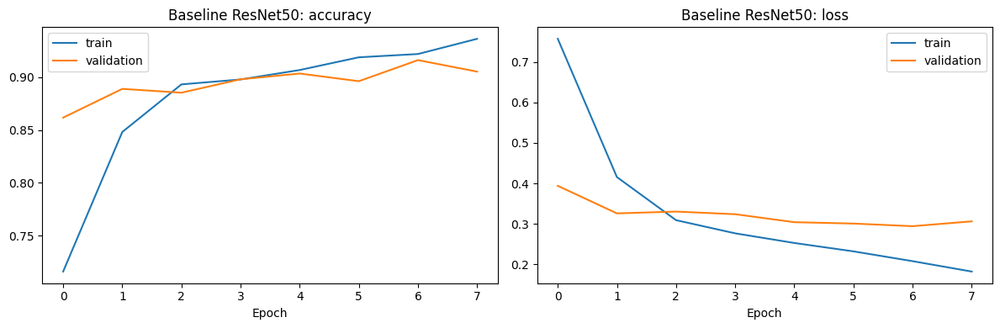

In [ ]:
baseline_model, baseline_backbone = build_stage_model(stage=None, attention="none", dropout=BEST_DROPOUT)
compile_model(baseline_model, BEST_LR)
baseline_history = train_model(baseline_model, "baseline_best", EPOCHS_ATTENTION)
models["Baseline"] = baseline_model
histories["Baseline"] = baseline_history
plot_history(baseline_history, "Baseline ResNet50")

In [ ]:
def fine_tune_last_stage(model, epochs, learning_rate=1e-5):
    # Locate the nested stage segments / backbone layers in this model.
    # This helper is intentionally conservative: fine-tuning varies by Keras graph structure.
    # Set epochs=0 to skip; the primary experiment remains valid as frozen-backbone transfer learning.
    if epochs <= 0:
        return None
    print("Fine-tuning note: unfreeze the final ResNet50 stage in your runtime-specific model graph.")
    print("For strict comparability, use the same unfreezing policy and epochs for every model.")
    return None

_ = fine_tune_last_stage(baseline_model, FINE_TUNE_EPOCHS, learning_rate=1e-5)


=== Training Channel at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 457ms/step - accuracy: 0.7046 - loss: 0.7602 - val_accuracy: 0.8564 - val_loss: 0.4101 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 314ms/step - accuracy: 0.8680 - loss: 0.3548 - val_accuracy: 0.8545 - val_loss: 0.3701 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.9031 - loss: 0.2769 - val_accuracy: 0.8709 - val_loss: 0.3370 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accuracy: 0.9093 - loss: 0.2438 - val_accuracy: 0.8945 - val_loss: 0.3127 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accuracy: 0.9190 - loss: 0.2172 - val_accuracy: 0.8945 - val_loss: 0.3073 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9303 - loss: 0.1972 - val_accuracy: 0.8927 - val_loss: 0.2939 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 309ms/step - ac

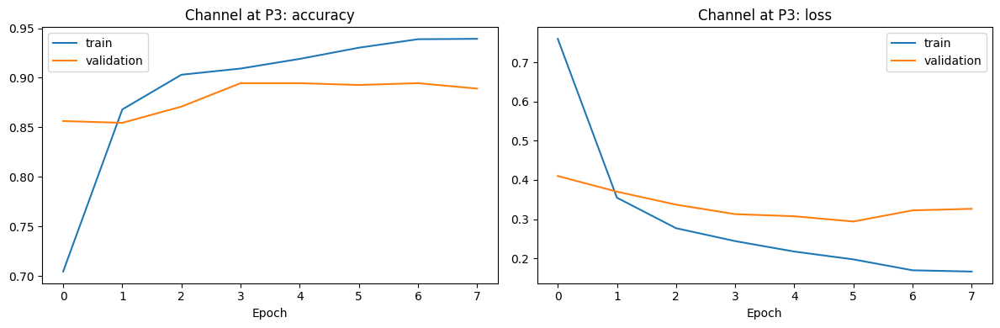


=== Training Spatial at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 48s 453ms/step - accuracy: 0.7318 - loss: 0.7502 - val_accuracy: 0.8564 - val_loss: 0.3924 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 324ms/step - accuracy: 0.8684 - loss: 0.3854 - val_accuracy: 0.8655 - val_loss: 0.3585 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.8926 - loss: 0.3035 - val_accuracy: 0.8891 - val_loss: 0.3149 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 320ms/step - accuracy: 0.9074 - loss: 0.2695 - val_accuracy: 0.9000 - val_loss: 0.3152 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.9259 - loss: 0.2195
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.9186 - loss: 0.2248 - val_accuracy: 0.8982 - val_loss: 0.3188 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - acc

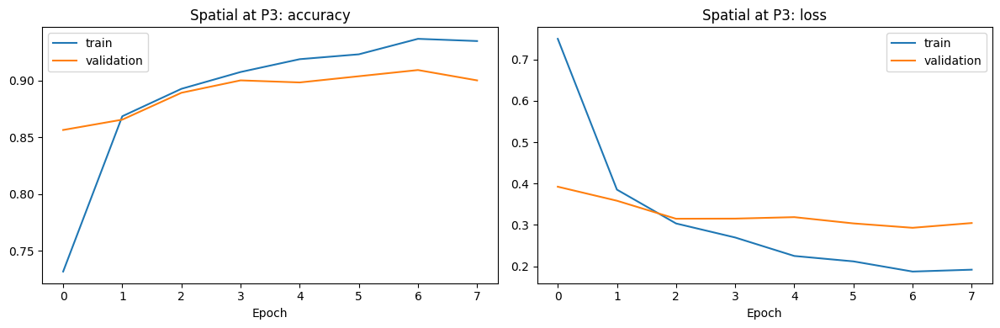


=== Training Channel→Spatial at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 462ms/step - accuracy: 0.6754 - loss: 0.8363 - val_accuracy: 0.8436 - val_loss: 0.4670 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.8564 - loss: 0.3695 - val_accuracy: 0.8800 - val_loss: 0.3890 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.8898 - loss: 0.2911 - val_accuracy: 0.8818 - val_loss: 0.3829 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 324ms/step - accuracy: 0.9054 - loss: 0.2567 - val_accuracy: 0.8927 - val_loss: 0.3835 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.9324 - loss: 0.2160
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 314ms/step - accuracy: 0.9202 - loss: 0.2189 - val_accuracy: 0.8873 - val_loss: 0.3940 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/st

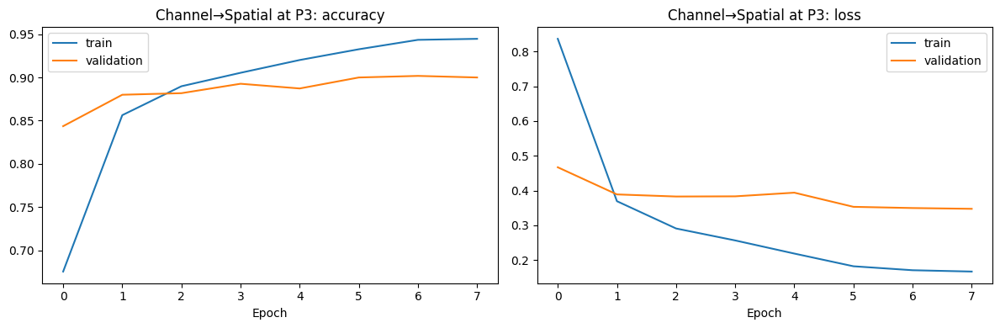


=== Training Spatial→Channel at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 460ms/step - accuracy: 0.6625 - loss: 0.8463 - val_accuracy: 0.8236 - val_loss: 0.4415 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.8824 - loss: 0.3402 - val_accuracy: 0.8745 - val_loss: 0.3746 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 326ms/step - accuracy: 0.9007 - loss: 0.2656 - val_accuracy: 0.8945 - val_loss: 0.3312 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9186 - loss: 0.2441 - val_accuracy: 0.8945 - val_loss: 0.3027 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9288 - loss: 0.1994 - val_accuracy: 0.8673 - val_loss: 0.3540 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.9386 - loss: 0.1722
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/st

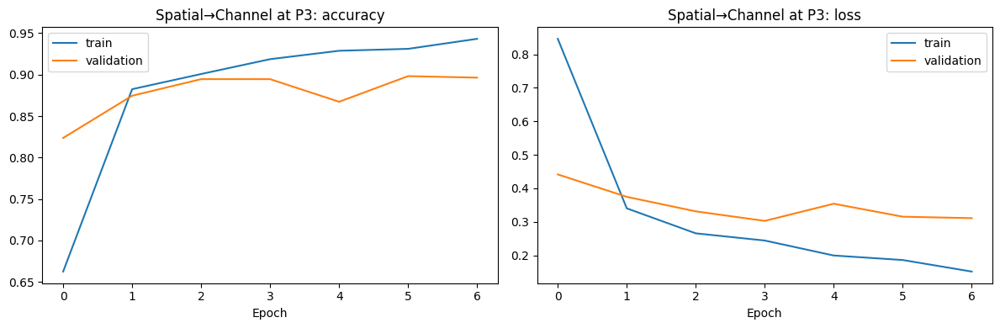


=== Training Self-Attention at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 53s 485ms/step - accuracy: 0.7411 - loss: 0.7439 - val_accuracy: 0.7818 - val_loss: 0.6088 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 340ms/step - accuracy: 0.8525 - loss: 0.4063 - val_accuracy: 0.8527 - val_loss: 0.4396 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 344ms/step - accuracy: 0.8715 - loss: 0.3395 - val_accuracy: 0.8782 - val_loss: 0.4301 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 337ms/step - accuracy: 0.9042 - loss: 0.2741 - val_accuracy: 0.8891 - val_loss: 0.4229 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 339ms/step - accuracy: 0.9132 - loss: 0.2356 - val_accuracy: 0.9018 - val_loss: 0.2974 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 332ms/step - accuracy: 0.9186 - loss: 0.2164 - val_accuracy: 0.8709 - val_loss: 0.4174 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 335ms/st

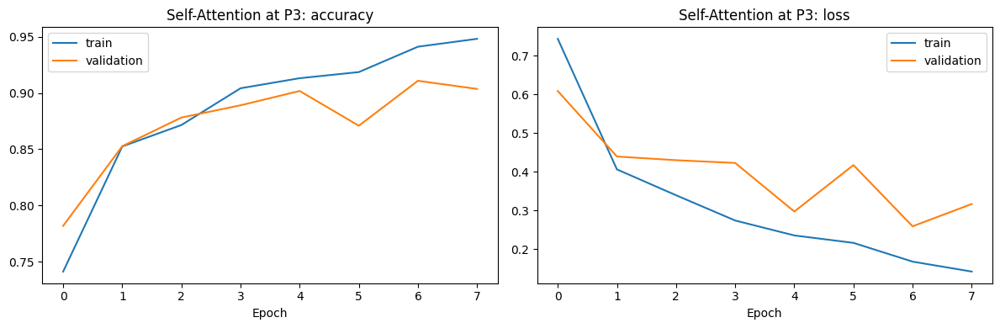


=== Training SE at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 47s 445ms/step - accuracy: 0.7283 - loss: 0.7127 - val_accuracy: 0.8455 - val_loss: 0.4328 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.8688 - loss: 0.3583 - val_accuracy: 0.8764 - val_loss: 0.3697 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accuracy: 0.9042 - loss: 0.2829 - val_accuracy: 0.8909 - val_loss: 0.3381 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 322ms/step - accuracy: 0.9151 - loss: 0.2386 - val_accuracy: 0.8964 - val_loss: 0.3407 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9206 - loss: 0.2081 - val_accuracy: 0.8945 - val_loss: 0.3269 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 311ms/step - accuracy: 0.9307 - loss: 0.2016 - val_accuracy: 0.8855 - val_loss: 0.3341 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accurac

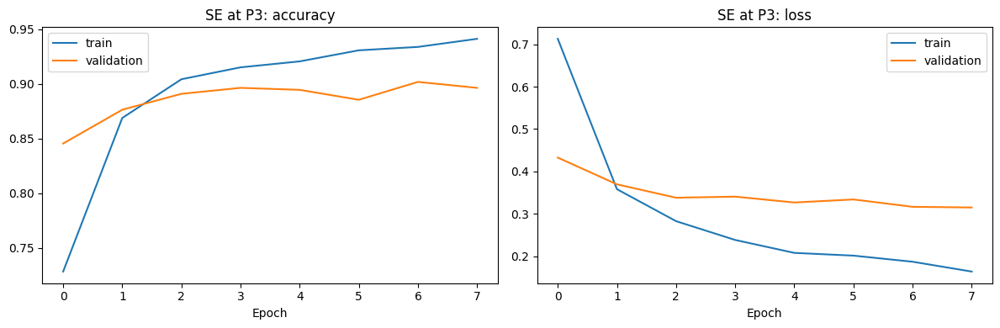


=== Training ECA at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 457ms/step - accuracy: 0.6532 - loss: 0.9180 - val_accuracy: 0.8091 - val_loss: 0.5089 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.8369 - loss: 0.4644 - val_accuracy: 0.8400 - val_loss: 0.4285 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.8727 - loss: 0.3560 - val_accuracy: 0.8473 - val_loss: 0.4093 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accuracy: 0.8949 - loss: 0.2960 - val_accuracy: 0.8709 - val_loss: 0.3728 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accuracy: 0.9027 - loss: 0.2698 - val_accuracy: 0.8564 - val_loss: 0.4036 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 316ms/step - accuracy: 0.9218 - loss: 0.2287 - val_accuracy: 0.8709 - val_loss: 0.3698 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 322ms/step - accura

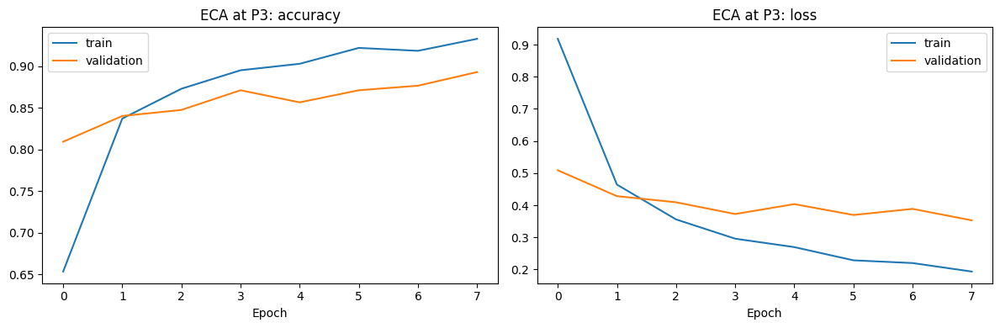


=== Training CBAM at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 467ms/step - accuracy: 0.7252 - loss: 0.7236 - val_accuracy: 0.8455 - val_loss: 0.4290 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 329ms/step - accuracy: 0.8653 - loss: 0.3646 - val_accuracy: 0.8618 - val_loss: 0.4037 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accuracy: 0.8910 - loss: 0.3084 - val_accuracy: 0.8618 - val_loss: 0.3767 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 314ms/step - accuracy: 0.9066 - loss: 0.2642 - val_accuracy: 0.8618 - val_loss: 0.3957 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.9098 - loss: 0.2451
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.9167 - loss: 0.2377 - val_accuracy: 0.8673 - val_loss: 0.4151 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accura

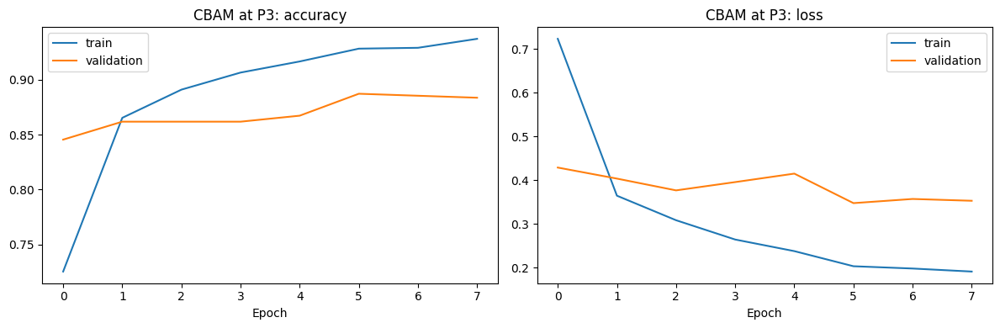


=== Training Coordinate at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 466ms/step - accuracy: 0.6368 - loss: 0.8933 - val_accuracy: 0.8273 - val_loss: 0.5090 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 330ms/step - accuracy: 0.8517 - loss: 0.4013 - val_accuracy: 0.8382 - val_loss: 0.4627 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 320ms/step - accuracy: 0.8824 - loss: 0.3148 - val_accuracy: 0.8655 - val_loss: 0.4326 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.9074 - loss: 0.2607 - val_accuracy: 0.8618 - val_loss: 0.4123 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 329ms/step - accuracy: 0.9179 - loss: 0.2257 - val_accuracy: 0.9000 - val_loss: 0.3395 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9284 - loss: 0.1973 - val_accuracy: 0.8800 - val_loss: 0.3963 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - 

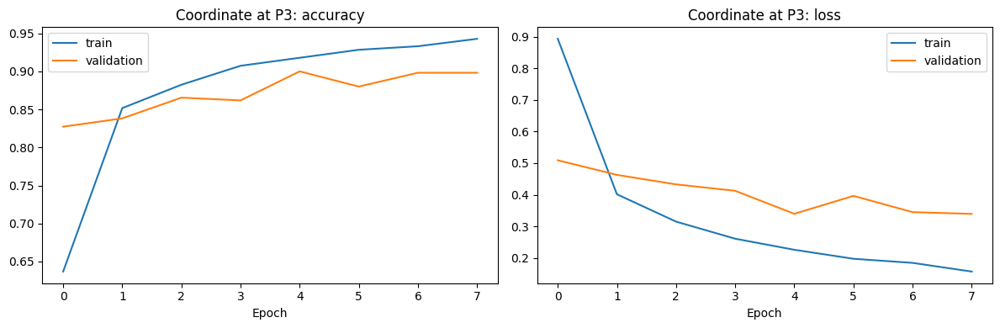

In [ ]:
ATTENTION_EXPERIMENTS = [
    ("Channel", "channel", "P3", "channel_spatial"),
    ("Spatial", "spatial", "P3", "channel_spatial"),
    ("Channel→Spatial", "channel_spatial", "P3", "channel_spatial"),
    ("Spatial→Channel", "channel_spatial", "P3", "spatial_channel"),
    ("Self-Attention", "self", "P3", "channel_spatial"),
    ("SE", "se", "P3", "channel_spatial"),
    ("ECA", "eca", "P3", "channel_spatial"),
    ("CBAM", "cbam", "P3", "channel_spatial"),
    ("Coordinate", "coordinate", "P3", "channel_spatial"),
]

for display_name, attn, pos, order in ATTENTION_EXPERIMENTS:
    print(f"\n=== Training {display_name} at {pos} ===")
    model, _ = build_stage_model(stage=pos, attention=attn, dropout=BEST_DROPOUT,
                                 attention_order=order)
    compile_model(model, BEST_LR)
    hist = train_model(model, f"attn_{display_name.replace('→','_').replace(' ','_')}", EPOCHS_ATTENTION)
    models[display_name] = model
    histories[display_name] = hist
    plot_history(hist, f"{display_name} at {pos}")
    del model
    gc.collect()


=== Training CS at P1 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 58s 527ms/step - accuracy: 0.3850 - loss: 1.5735 - val_accuracy: 0.7091 - val_loss: 0.8125 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 373ms/step - accuracy: 0.7322 - loss: 0.7286 - val_accuracy: 0.8000 - val_loss: 0.5343 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 376ms/step - accuracy: 0.7898 - loss: 0.5619 - val_accuracy: 0.8127 - val_loss: 0.5034 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 372ms/step - accuracy: 0.8400 - loss: 0.4522 - val_accuracy: 0.8473 - val_loss: 0.4512 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 375ms/step - accuracy: 0.8470 - loss: 0.4060 - val_accuracy: 0.8582 - val_loss: 0.4347 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 361ms/step - accuracy: 0.8774 - loss: 0.3486 - val_accuracy: 0.8564 - val_loss: 0.4467 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy

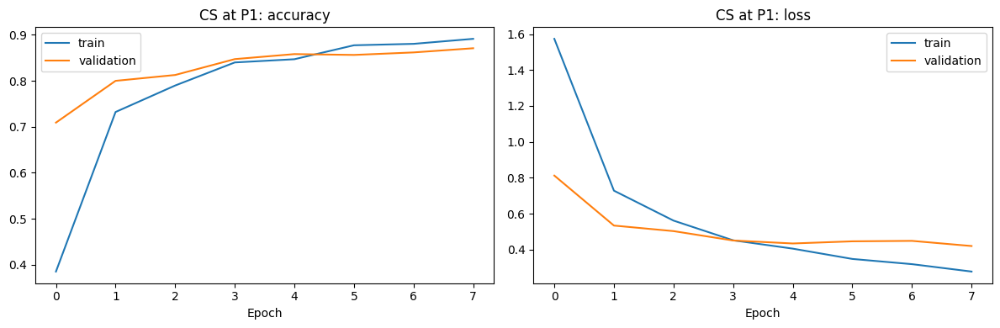


=== Training CS at P2 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 52s 489ms/step - accuracy: 0.5804 - loss: 1.0449 - val_accuracy: 0.7982 - val_loss: 0.5077 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 357ms/step - accuracy: 0.8431 - loss: 0.4291 - val_accuracy: 0.8727 - val_loss: 0.3437 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 349ms/step - accuracy: 0.8828 - loss: 0.3249 - val_accuracy: 0.8927 - val_loss: 0.3371 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 350ms/step - accuracy: 0.8933 - loss: 0.2791 - val_accuracy: 0.8982 - val_loss: 0.3193 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 344ms/step - accuracy: 0.9163 - loss: 0.2416 - val_accuracy: 0.8927 - val_loss: 0.3254 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 349ms/step - accuracy: 0.9202 - loss: 0.2074 - val_accuracy: 0.9000 - val_loss: 0.2837 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 350ms/step - accurac

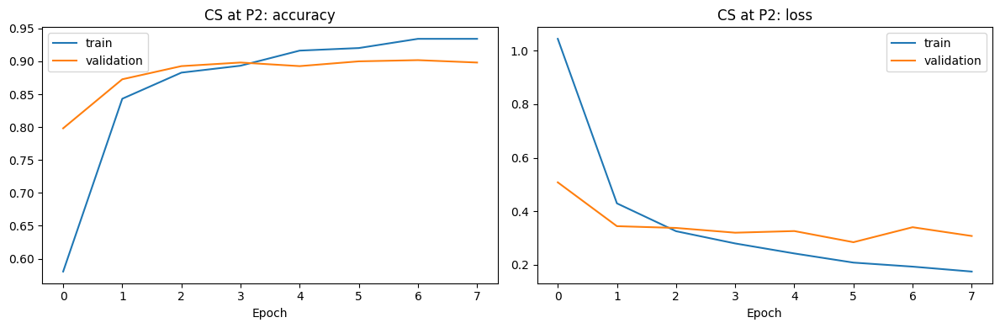


=== Training CS at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 456ms/step - accuracy: 0.7096 - loss: 0.7543 - val_accuracy: 0.8364 - val_loss: 0.4163 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.8809 - loss: 0.3414 - val_accuracy: 0.8727 - val_loss: 0.3224 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 314ms/step - accuracy: 0.9046 - loss: 0.2679 - val_accuracy: 0.8673 - val_loss: 0.3620 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accuracy: 0.9167 - loss: 0.2443 - val_accuracy: 0.8927 - val_loss: 0.2985 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.9264 - loss: 0.2185 - val_accuracy: 0.8945 - val_loss: 0.2939 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.9350 - loss: 0.1875 - val_accuracy: 0.9127 - val_loss: 0.2841 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 313ms/step - accurac

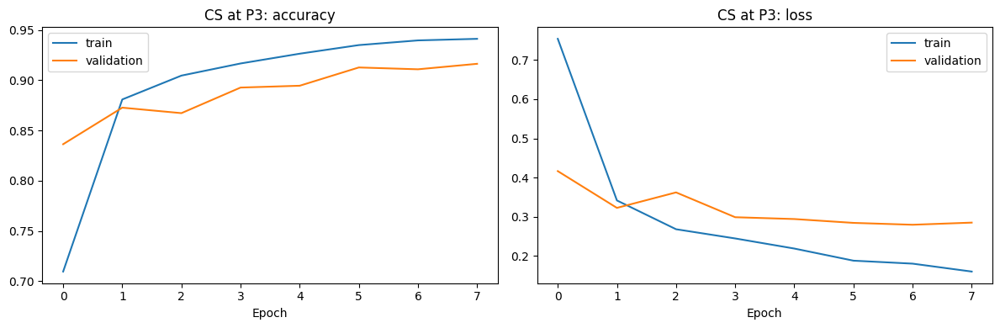


=== Training CS at P4 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 49s 452ms/step - accuracy: 0.7742 - loss: 0.6409 - val_accuracy: 0.8455 - val_loss: 0.3920 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 318ms/step - accuracy: 0.9011 - loss: 0.2874 - val_accuracy: 0.8909 - val_loss: 0.3108 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 306ms/step - accuracy: 0.9260 - loss: 0.2155 - val_accuracy: 0.8891 - val_loss: 0.3361 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.9460 - loss: 0.1477
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 317ms/step - accuracy: 0.9478 - loss: 0.1505 - val_accuracy: 0.8982 - val_loss: 0.3466 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 306ms/step - accuracy: 0.9599 - loss: 0.1102 - val_accuracy: 0.8836 - val_loss: 0.3349 - learning_rate: 3.0000e-04
Epoch 5: early stopping
Restoring model weights from the e

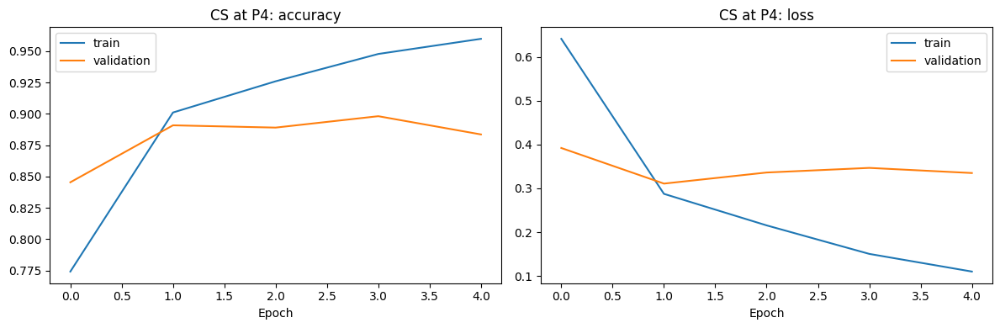

In [ ]:
POSITION_EXPERIMENTS = [("CS at P1", "P1"), ("CS at P2", "P2"),
                        ("CS at P3", "P3"), ("CS at P4", "P4")]
for display_name, pos in POSITION_EXPERIMENTS:
    if display_name in models:
        continue
    print(f"\n=== Training {display_name} ===")
    model, _ = build_stage_model(stage=pos, attention="channel_spatial",
                                 dropout=BEST_DROPOUT, attention_order="channel_spatial")
    compile_model(model, BEST_LR)
    hist = train_model(model, f"position_{pos}", EPOCHS_ATTENTION)
    models[display_name] = model
    histories[display_name] = hist
    plot_history(hist, display_name)
    gc.collect()

In [ ]:
results = []
predictions = {}
for name, model in models.items():
    try:
        row, yt, yp, probs = evaluate_model(model, name, test_ds)
        results.append(row)
        predictions[name] = (yt, yp, probs)
    except Exception as e:
        print(f"Evaluation failed for {name}: {e}")

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)
display(results_df)
results_df.to_csv("attention_results.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Total Params,Trainable Params,Inference ms/image
9,Coordinate,0.911071,0.909966,0.909249,0.909458,23796677,208965,17.504523
6,SE,0.911071,0.908661,0.909760,0.909029,23730117,142405,16.603496
12,CS at P3,0.909256,0.904834,0.911149,0.907353,23730215,142503,17.705658
5,Self-Attention,0.907441,0.903926,0.910928,0.906645,24909957,1322245,17.714574
2,Spatial,0.905626,0.903175,0.906116,0.904301,23598055,10343,17.451556
3,Channel→Spatial,0.900181,0.901404,0.898796,0.899649,23730215,142503,17.687590
0,Baseline,0.898367,0.895401,0.899062,0.896583,23597957,10245,19.458545
4,Spatial→Channel,0.896552,0.904377,0.897266,0.896322,23730215,142503,17.750167
13,CS at P4,0.896552,0.892733,0.898011,0.894840,24124519,536807,17.951180
1,Channel,0.892922,0.888750,0.895903,0.891178,23730117,142405,16.962944



=== Training Channel->Spatial at P3 with spatial kernel 3x3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 51s 465ms/step - accuracy: 0.7322 - loss: 0.7259 - val_accuracy: 0.8491 - val_loss: 0.3877 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.8739 - loss: 0.3386 - val_accuracy: 0.8691 - val_loss: 0.3673 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.9004 - loss: 0.2842 - val_accuracy: 0.8836 - val_loss: 0.3273 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 325ms/step - accuracy: 0.9206 - loss: 0.2239 - val_accuracy: 0.8964 - val_loss: 0.3154 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.9330 - loss: 0.1924 - val_accuracy: 0.9000 - val_loss: 0.3119 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9315 - loss: 0.1792 - val_accuracy: 0.9000 - val_loss: 0.3191 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━

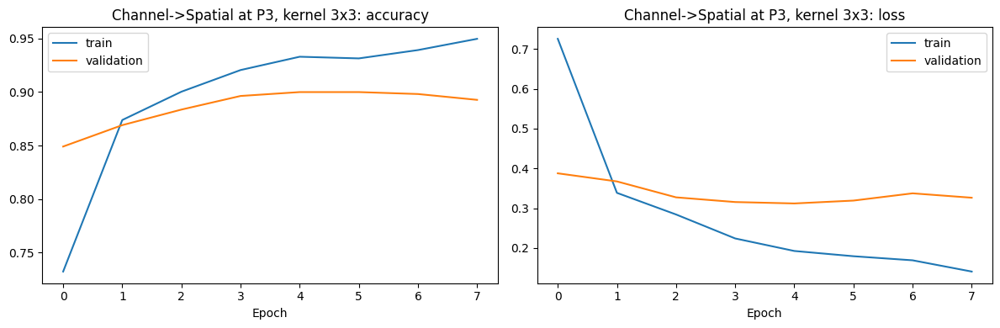


=== Training Channel->Spatial at P3 with spatial kernel 5x5 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 466ms/step - accuracy: 0.7501 - loss: 0.6865 - val_accuracy: 0.8673 - val_loss: 0.3475 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.8793 - loss: 0.3307 - val_accuracy: 0.8764 - val_loss: 0.3501 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.9011 - loss: 0.2731 - val_accuracy: 0.8891 - val_loss: 0.3134 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 327ms/step - accuracy: 0.9085 - loss: 0.2428 - val_accuracy: 0.8964 - val_loss: 0.2912 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 318ms/step - accuracy: 0.9237 - loss: 0.2174 - val_accuracy: 0.8873 - val_loss: 0.2988 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step - accuracy: 0.9221 - loss: 0.1981
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━

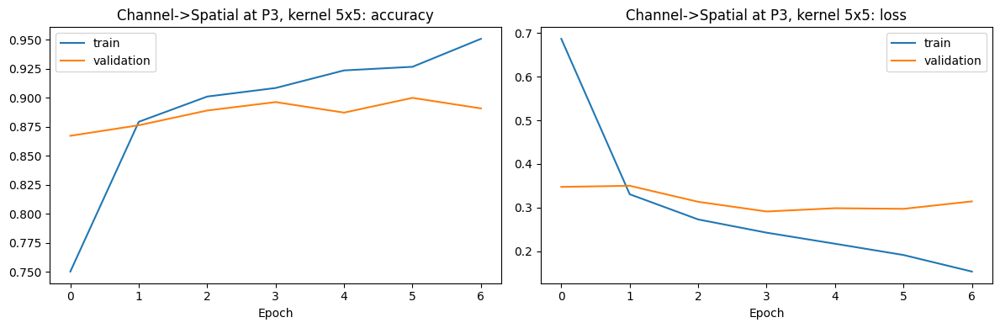


=== Training Channel->Spatial at P3 with spatial kernel 7x7 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 464ms/step - accuracy: 0.6894 - loss: 0.8002 - val_accuracy: 0.8491 - val_loss: 0.4456 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 329ms/step - accuracy: 0.8754 - loss: 0.3469 - val_accuracy: 0.8655 - val_loss: 0.3938 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 326ms/step - accuracy: 0.9015 - loss: 0.2762 - val_accuracy: 0.8891 - val_loss: 0.3531 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 326ms/step - accuracy: 0.9093 - loss: 0.2459 - val_accuracy: 0.8909 - val_loss: 0.3579 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.9295 - loss: 0.1936
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 315ms/step - accuracy: 0.9284 - loss: 0.2018 - val_accuracy: 0.8891 - val_loss: 0.3540 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━

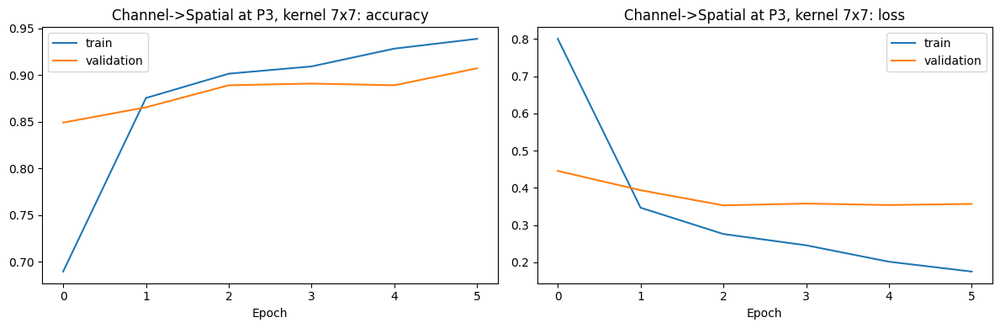

In [ ]:
KERNEL_SIZES = [3, 5, 7]

for k in KERNEL_SIZES:
    name = f"Kernel {k}x{k}"
    print(f"\n=== Training Channel->Spatial at P3 with spatial kernel {k}x{k} ===")
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)          # same initialisation seed for every run
    model, _ = build_stage_model(stage="P3", attention="channel_spatial",
                                 dropout=BEST_DROPOUT, spatial_kernel=k,
                                 attention_order="channel_spatial")
    compile_model(model, BEST_LR)
    hist = train_model(model, f"attn_kernel_{k}x{k}", EPOCHS_ATTENTION)
    models[name] = model
    histories[name] = hist
    plot_history(hist, f"Channel->Spatial at P3, kernel {k}x{k}")
    gc.collect()

,Spatial Kernel,Accuracy,Macro Precision,Macro Recall,Macro F1,Total Params,Inference ms/image
0,3x3,0.894737,0.892717,0.893775,0.892419,23730135,17.820285
1,5x5,0.891107,0.885941,0.893498,0.888776,23730167,17.840018
2,7x7,0.887477,0.888002,0.884129,0.885822,23730215,17.771563


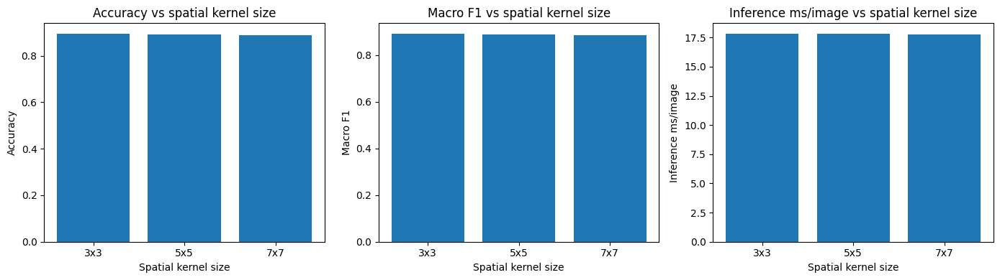

In [ ]:
kernel_rows = []
for k in KERNEL_SIZES:
    name = f"Kernel {k}x{k}"
    row, yt, yp, probs = evaluate_model(models[name], name, test_ds)
    predictions[name] = (yt, yp, probs)
    kernel_rows.append({
        "Spatial Kernel": f"{k}x{k}",
        "Accuracy": row["Accuracy"],
        "Macro Precision": row["Macro Precision"],
        "Macro Recall": row["Macro Recall"],
        "Macro F1": row["Macro F1"],
        "Total Params": row["Total Params"],
        "Inference ms/image": row["Inference ms/image"],
    })

kernel_df = pd.DataFrame(kernel_rows)
display(kernel_df)
kernel_df.to_csv("kernel_size_results.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Accuracy", "Macro F1", "Inference ms/image"]):
    ax.bar(kernel_df["Spatial Kernel"], kernel_df[col])
    ax.set_title(f"{col} vs spatial kernel size")
    ax.set_xlabel("Spatial kernel size")
    ax.set_ylabel(col)
plt.tight_layout(); plt.show()

=== Training A5: Combined attention at P3 ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 57s 519ms/step - accuracy: 0.6438 - loss: 0.9073 - val_accuracy: 0.8200 - val_loss: 0.5077 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 355ms/step - accuracy: 0.8591 - loss: 0.3825 - val_accuracy: 0.8582 - val_loss: 0.4567 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 354ms/step - accuracy: 0.9000 - loss: 0.2906 - val_accuracy: 0.8927 - val_loss: 0.4217 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 349ms/step - accuracy: 0.9202 - loss: 0.2209 - val_accuracy: 0.9164 - val_loss: 0.3189 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 355ms/step - accuracy: 0.9214 - loss: 0.2186 - val_accuracy: 0.9236 - val_loss: 0.2954 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 339ms/step - accuracy: 0.9443 - loss: 0.1627 - val_accuracy: 0.9127 - val_loss: 0.2796 - learning_rate: 0.0010
Epoch 7/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 3

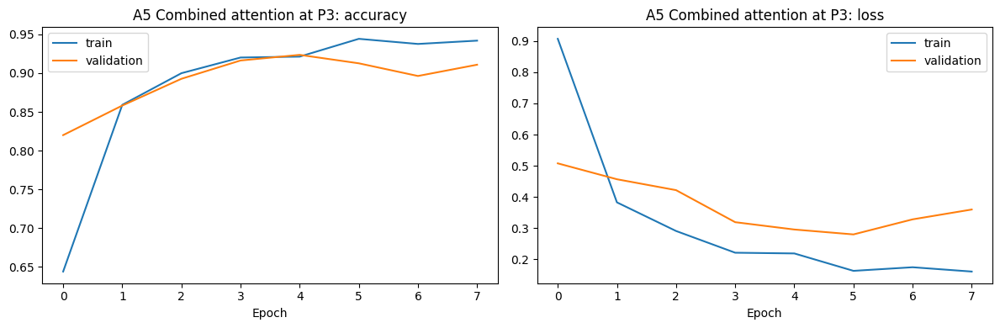

In [ ]:
if "_orig_apply_attention" not in globals():
    _orig_apply_attention = apply_attention

def apply_attention(x, attention, reduction=16, spatial_kernel=7, order="channel_spatial", name="attn"):
    if attention == "combined_all":
        x = channel_attention(x, reduction, name=f"{name}_channel")
        x = spatial_attention(x, spatial_kernel, name=f"{name}_spatial")
        return self_attention(x, name=f"{name}_self")
    return _orig_apply_attention(x, attention, reduction, spatial_kernel, order, name)

if "Combined (C+S+SA)" not in models:
    print("=== Training A5: Combined attention at P3 ===")
    tf.random.set_seed(SEED)
    model, _ = build_stage_model(stage="P3", attention="combined_all", dropout=BEST_DROPOUT)
    compile_model(model, BEST_LR)
    hist = train_model(model, "attn_Combined", EPOCHS_ATTENTION)
    models["Combined (C+S+SA)"] = model
    histories["Combined (C+S+SA)"] = hist
    plot_history(hist, "Combined attention at P3")
    gc.collect()


=== Training CS at P3+P4 (Channel->Spatial at P3, P4) ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 52s 480ms/step - accuracy: 0.3562 - loss: 1.4055 - val_accuracy: 0.7909 - val_loss: 0.5368 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 324ms/step - accuracy: 0.8431 - loss: 0.4173 - val_accuracy: 0.8382 - val_loss: 0.4301 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 328ms/step - accuracy: 0.8965 - loss: 0.2781 - val_accuracy: 0.8764 - val_loss: 0.3568 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 25s 310ms/step - accuracy: 0.9210 - loss: 0.2207 - val_accuracy: 0.8564 - val_loss: 0.4461 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step - accuracy: 0.9329 - loss: 0.1806
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━━━━━━━━━━━━━━ 26s 323ms/step - accuracy: 0.9404 - loss: 0.1683 - val_accuracy: 0.8945 - val_loss: 0.3878 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━

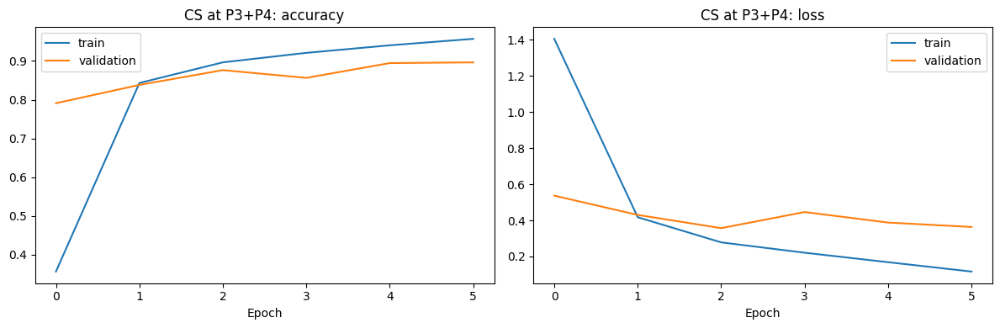


=== Training CS at P2+P3+P4 (Channel->Spatial at P2, P3, P4) ===
Epoch 1/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 58s 521ms/step - accuracy: 0.6423 - loss: 0.9072 - val_accuracy: 0.8436 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 2/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 356ms/step - accuracy: 0.8638 - loss: 0.3648 - val_accuracy: 0.8582 - val_loss: 0.4130 - learning_rate: 0.0010
Epoch 3/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 347ms/step - accuracy: 0.9011 - loss: 0.2590 - val_accuracy: 0.8673 - val_loss: 0.3807 - learning_rate: 0.0010
Epoch 4/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 28s 341ms/step - accuracy: 0.9249 - loss: 0.1990 - val_accuracy: 0.8873 - val_loss: 0.3721 - learning_rate: 0.0010
Epoch 5/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 27s 331ms/step - accuracy: 0.9420 - loss: 0.1466 - val_accuracy: 0.8782 - val_loss: 0.4168 - learning_rate: 0.0010
Epoch 6/8
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.9581 - loss: 0.1195
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
81/81 ━━━━━━━

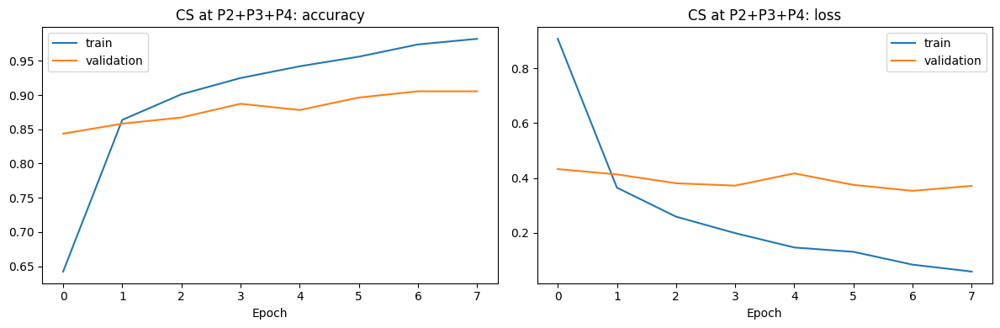

In [ ]:
MULTI_EXPERIMENTS = [("CS at P3+P4", ["P3", "P4"]),
                     ("CS at P2+P3+P4", ["P2", "P3", "P4"])]

for name, stages in MULTI_EXPERIMENTS:
    if name in models:
        continue
    print(f"\n=== Training {name} (Channel->Spatial at {', '.join(stages)}) ===")
    tf.random.set_seed(SEED)
    model, _ = build_stage_model(stage=None, attention="channel_spatial", dropout=BEST_DROPOUT,
                                 multi_stages=stages, attention_order="channel_spatial")
    compile_model(model, BEST_LR)
    hist = train_model(model, "multi_" + "_".join(stages), EPOCHS_ATTENTION)
    models[name] = model
    histories[name] = hist
    plot_history(hist, name)
    gc.collect()

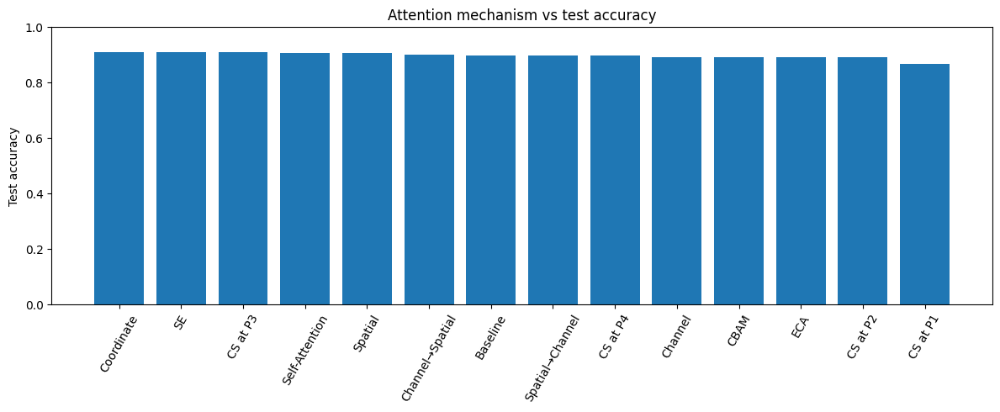

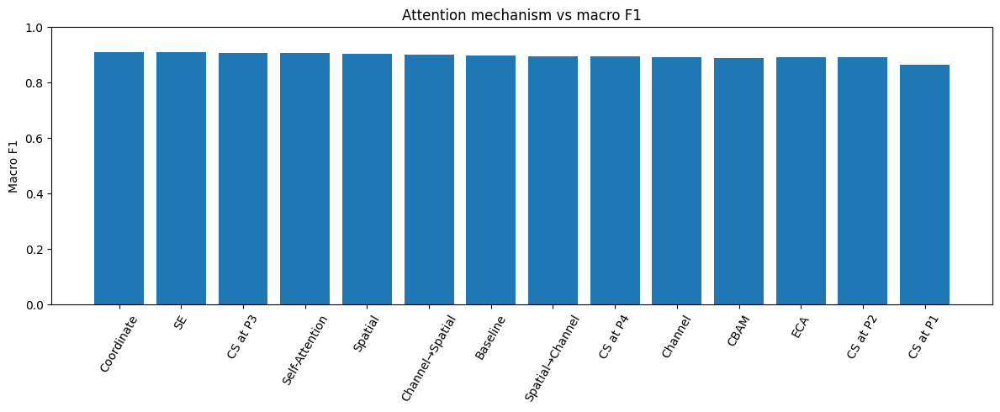

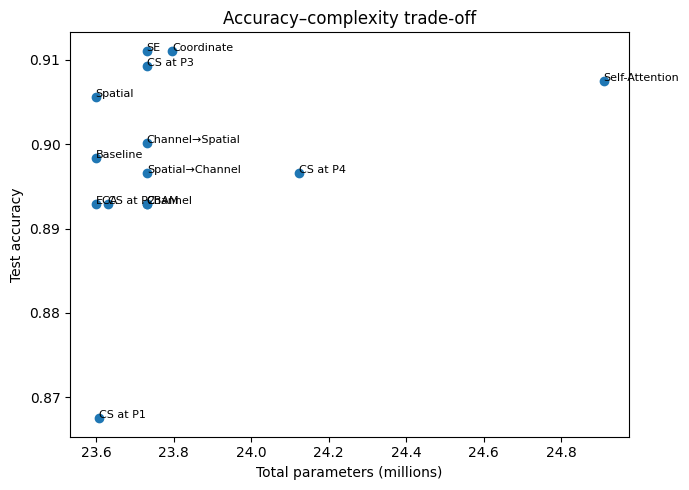

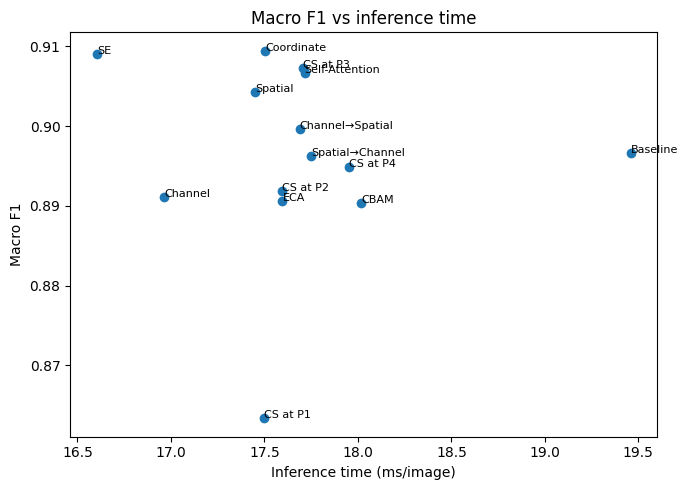

In [ ]:
if len(results_df):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(results_df["Model"], results_df["Accuracy"])
    ax.set_ylabel("Test accuracy"); ax.set_ylim(0, 1)
    ax.set_title("Attention mechanism vs test accuracy")
    ax.tick_params(axis="x", rotation=60)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(results_df["Model"], results_df["Macro F1"])
    ax.set_ylabel("Macro F1"); ax.set_ylim(0, 1)
    ax.set_title("Attention mechanism vs macro F1")
    ax.tick_params(axis="x", rotation=60)
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(results_df["Total Params"]/1e6, results_df["Accuracy"])
    for _, r in results_df.iterrows():
        ax.annotate(r["Model"], (r["Total Params"]/1e6, r["Accuracy"]), fontsize=8)
    ax.set_xlabel("Total parameters (millions)"); ax.set_ylabel("Test accuracy")
    ax.set_title("Accuracy–complexity trade-off")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(results_df["Inference ms/image"], results_df["Macro F1"])
    for _, r in results_df.iterrows():
        ax.annotate(r["Model"], (r["Inference ms/image"], r["Macro F1"]), fontsize=8)
    ax.set_xlabel("Inference time (ms/image)"); ax.set_ylabel("Macro F1")
    ax.set_title("Macro F1 vs inference time")
    plt.tight_layout(); plt.show()

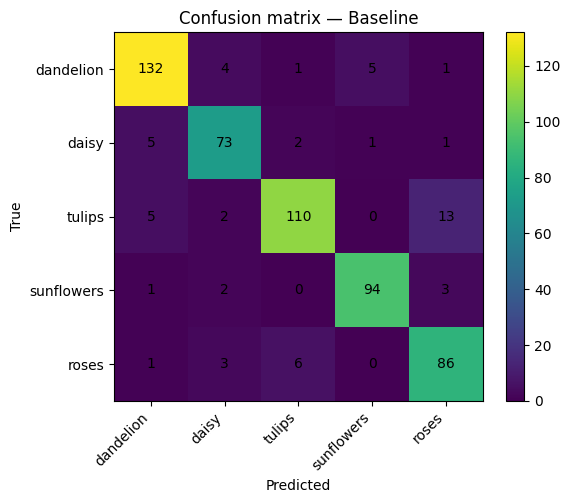

              precision    recall  f1-score   support

   dandelion       0.92      0.92      0.92       143
       daisy       0.87      0.89      0.88        82
      tulips       0.92      0.85      0.88       130
  sunflowers       0.94      0.94      0.94       100
       roses       0.83      0.90      0.86        96

    accuracy                           0.90       551
   macro avg       0.90      0.90      0.90       551
weighted avg       0.90      0.90      0.90       551



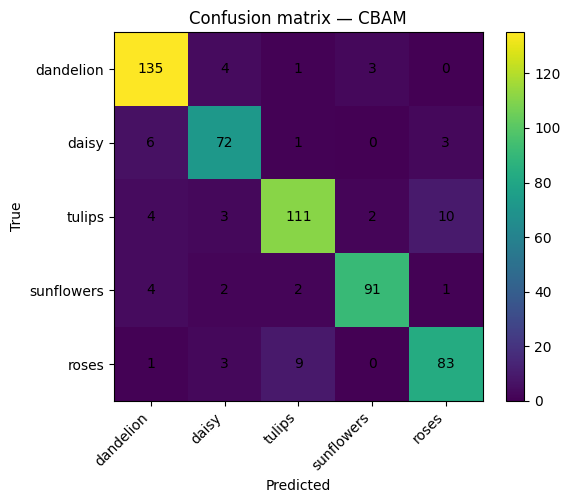

              precision    recall  f1-score   support

   dandelion       0.90      0.94      0.92       143
       daisy       0.86      0.88      0.87        82
      tulips       0.90      0.85      0.87       130
  sunflowers       0.95      0.91      0.93       100
       roses       0.86      0.86      0.86        96

    accuracy                           0.89       551
   macro avg       0.89      0.89      0.89       551
weighted avg       0.89      0.89      0.89       551



In [ ]:
def plot_confusion_for(name):
    if name not in predictions:
        print("No predictions cached for", name); return
    yt, yp, _ = predictions[name]
    cm = confusion_matrix(yt, yp, labels=np.arange(NUM_CLASSES))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"Confusion matrix — {name}")
    ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
    ax.set_yticks(range(NUM_CLASSES), class_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
    print(classification_report(yt, yp, target_names=class_names, zero_division=0))

plot_confusion_for("Baseline")
plot_confusion_for("CBAM")

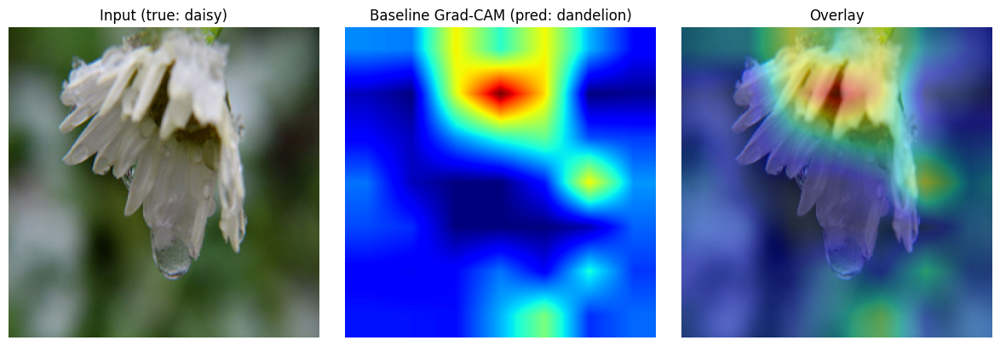

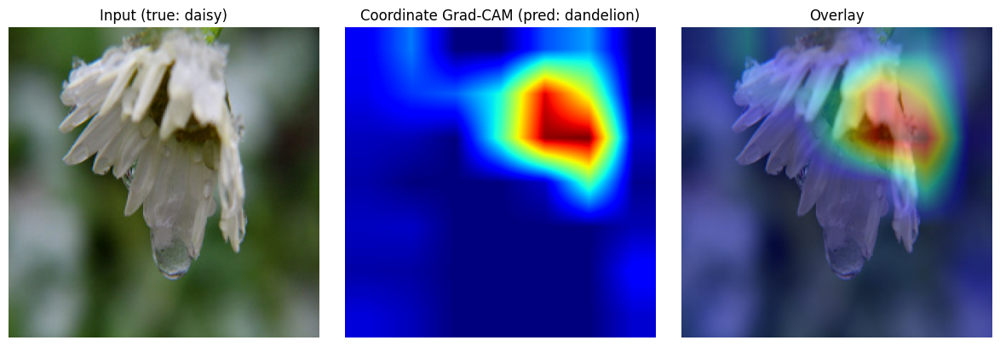

In [ ]:
_GRADCAM_CACHE = {}

def gradcam_heatmap(model, image_batch, class_index=None, layer_name=None, return_pred=False):
    key = (model, layer_name)
    if key not in _GRADCAM_CACHE:
        target = model.get_layer(layer_name).output if layer_name else model.get_layer("gap").input
        _GRADCAM_CACHE[key] = tf.keras.Model(model.inputs, [target, model.output])
    grad_model = _GRADCAM_CACHE[key]
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(image_batch, training=False)
        if class_index is None:
            class_index = int(tf.argmax(preds[0]))
        score = preds[:, class_index]
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    heatmap = tf.nn.relu(tf.reduce_sum(weights * conv_out, axis=-1))
    heatmap = heatmap / (tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8)
    heat = heatmap[0].numpy()
    return (heat, int(class_index)) if return_pred else heat

def gradcam_overlay(model, raw, class_index=None):
    # returns (heat map resized to IMG_SIZE x IMG_SIZE, predicted class)
    batch = tf.expand_dims(preprocess_input(raw.astype("float32").copy()), 0)
    heat, pred = gradcam_heatmap(model, batch, class_index, return_pred=True)
    heat = tf.image.resize(heat[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
    return heat, pred

def show_gradcam(model, name, image_index=0):
    raw = x_test[image_index].astype("float32")
    heat, pred = gradcam_overlay(model, raw)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(raw.astype("uint8")); axes[0].set_title(f"Input (true: {class_names[y_test[image_index]]})")
    axes[1].imshow(heat, cmap="jet"); axes[1].set_title(f"{name} Grad-CAM (pred: {class_names[pred]})")
    axes[2].imshow(raw.astype("uint8")); axes[2].imshow(heat, cmap="jet", alpha=0.4)
    axes[2].set_title("Overlay")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

show_gradcam(models["Baseline"], "Baseline", image_index=0)
_sel = globals().get("SELECTED_ATTENTION")
if _sel in models:
    show_gradcam(models[_sel], _sel, image_index=0)

Correct images: [1, 3, 4] | Misclassified images: [0, 7]


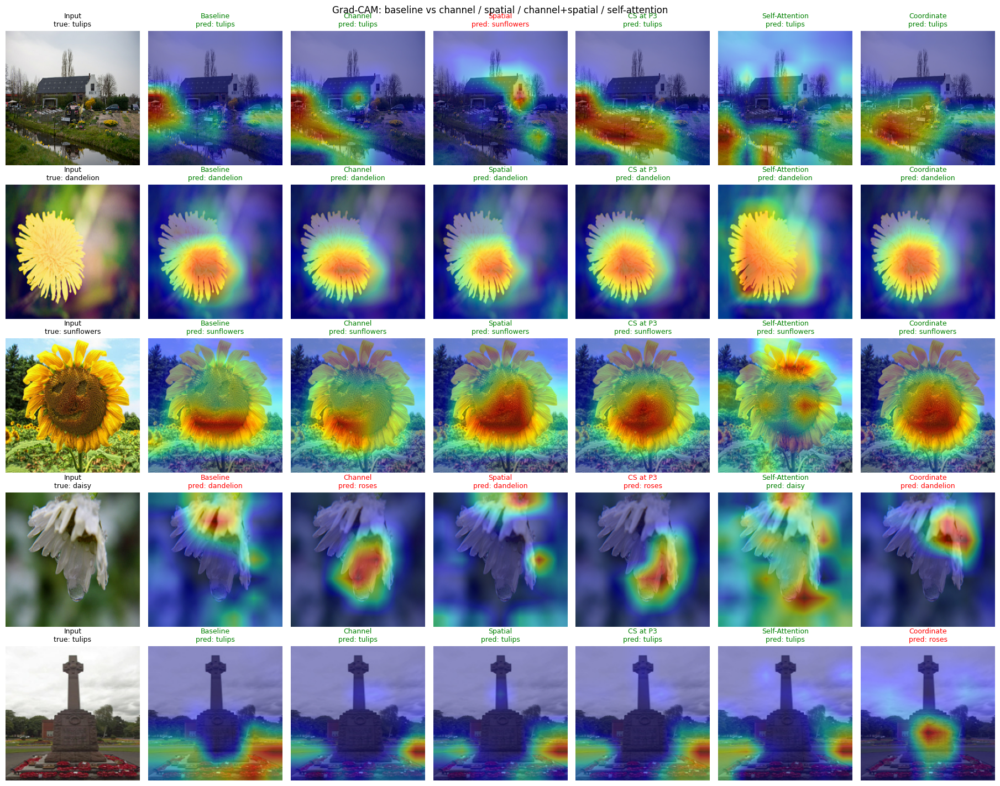

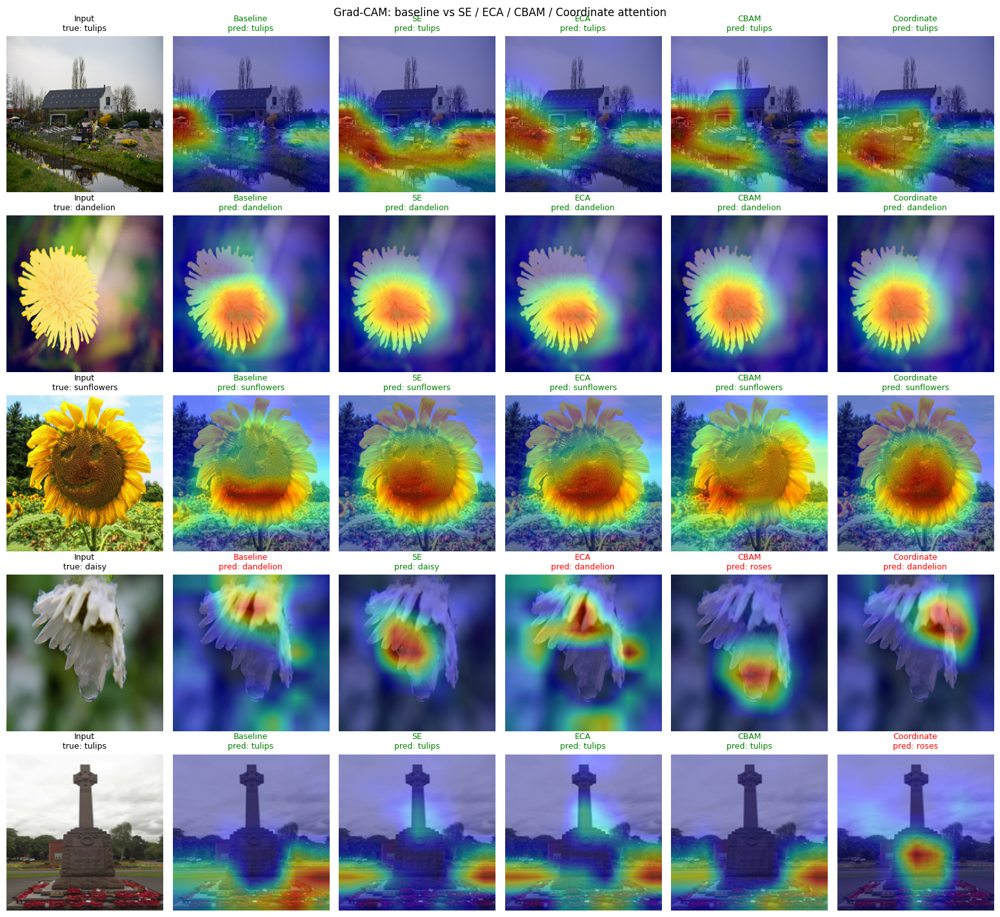

,Model,"Coverage, correct (heat>0.5)","Coverage, misclassified",n misclassified
0,Baseline,0.1903,0.2188,4
1,Channel,0.1873,0.1463,4
2,Spatial,0.1872,0.0925,5
3,CS at P3,0.2139,0.1202,8
4,Self-Attention,0.3483,0.2072,4
5,SE,0.1998,0.0925,4
6,ECA,0.1943,0.1734,6
7,CBAM,0.1949,0.1673,7
8,Coordinate,0.2194,0.1015,5


In [ ]:
pb_pred, ps_pred = predictions["Baseline"][1], predictions[SELECTED_ATTENTION][1]
n_test = len(y_test)

sel_correct, seen = [], set()
for i in range(n_test):
    if pb_pred[i] == y_test[i] == ps_pred[i] and y_test[i] not in seen:
        sel_correct.append(i); seen.add(y_test[i])
    if len(sel_correct) == 3:
        break
wrong_att = [i for i in range(n_test) if ps_pred[i] != y_test[i]]
wrong_any = [i for i in range(n_test) if pb_pred[i] != y_test[i] and i not in wrong_att]
sel_wrong = (wrong_att + wrong_any)[:2]
GRID_IDX = sel_correct + sel_wrong
print("Correct images:", sel_correct, "| Misclassified images:", sel_wrong)

def gradcam_grid(model_names, image_idxs, title):
    model_names = [n for n in model_names if n in models]
    n_r, n_c = len(image_idxs), 1 + len(model_names)
    fig, axes = plt.subplots(n_r, n_c, figsize=(2.6 * n_c, 2.9 * n_r), squeeze=False)
    for r, idx in enumerate(image_idxs):
        raw = x_test[idx].astype("float32")
        axes[r, 0].imshow(raw.astype("uint8"))
        axes[r, 0].set_title(f"Input\ntrue: {class_names[y_test[idx]]}", fontsize=9)
        for c, name in enumerate(model_names, start=1):
            heat, pred = gradcam_overlay(models[name], raw)
            axes[r, c].imshow(raw.astype("uint8")); axes[r, c].imshow(heat, cmap="jet", alpha=0.45)
            axes[r, c].set_title(f"{name}\npred: {class_names[pred]}", fontsize=9,
                                 color="green" if pred == y_test[idx] else "red")
    for ax in axes.ravel(): ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

main_set = ["Baseline", "Channel", "Spatial", "CS at P3", "Self-Attention"]
if SELECTED_ATTENTION not in main_set:
    main_set.append(SELECTED_ATTENTION)
gradcam_grid(main_set, GRID_IDX, "Grad-CAM: baseline vs channel / spatial / channel+spatial / self-attention")
gradcam_grid(["Baseline", "SE", "ECA", "CBAM", "Coordinate"], GRID_IDX,
             "Grad-CAM: baseline vs SE / ECA / CBAM / Coordinate attention")

# Quantitative description of the Grad-CAM maps (Section 30.1: coverage / compactness)
def m_(v): return float(np.mean(v)) if len(v) else float("nan")
cov_rows = []
for name in [n for n in ["Baseline", "Channel", "Spatial", "CS at P3", "Self-Attention", "SE", "ECA", "CBAM", "Coordinate"]
             if n in models]:
    cov_ok, cov_bad = [], []
    for i in range(min(60, n_test)):
        heat, pred = gradcam_overlay(models[name], x_test[i].astype("float32"))
        (cov_ok if pred == y_test[i] else cov_bad).append(float((heat > 0.5).mean()))
    cov_rows.append({"Model": name, "Coverage, correct (heat>0.5)": m_(cov_ok),
                     "Coverage, misclassified": m_(cov_bad), "n misclassified": len(cov_bad)})
cov_df = pd.DataFrame(cov_rows)
display(cov_df.round(4))
cov_df.to_csv("gradcam_coverage.csv", index=False)

Layer output shape: (1, 14, 14, 1)


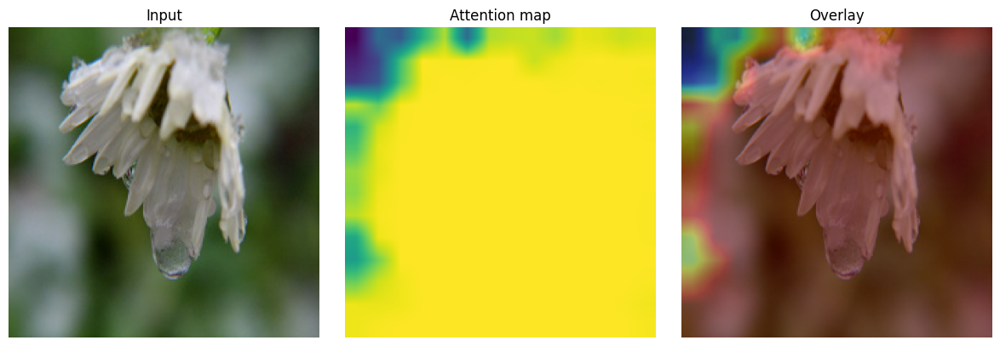

In [ ]:
def show_intermediate_layer(model, layer_name, image_index=0):
    raw = x_test[image_index].astype("float32")
    batch = tf.expand_dims(preprocess_input(raw.copy()), 0)
    layer = model.get_layer(layer_name)
    probe = tf.keras.Model(model.inputs, layer.output)
    output = probe(batch, training=False).numpy()
    print("Layer output shape:", output.shape)
    if output.ndim == 4 and output.shape[-1] == 1:
        heat = output[0, :, :, 0]
        heat = tf.image.resize(heat[..., None], (IMG_SIZE, IMG_SIZE)).numpy().squeeze()
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(raw.astype("uint8")); axes[0].set_title("Input")
        axes[1].imshow(heat, cmap="viridis"); axes[1].set_title("Attention map")
        axes[2].imshow(raw.astype("uint8")); axes[2].imshow(heat, cmap="jet", alpha=0.4)
        axes[2].set_title("Overlay")
        for ax in axes: ax.axis("off")
        plt.tight_layout(); plt.show()
    elif output.ndim == 4:
        feature = output[0]
        fig, axes = plt.subplots(1, min(8, feature.shape[-1]), figsize=(16, 3))
        for i, ax in enumerate(np.array(axes).reshape(-1)):
            ax.imshow(feature[:, :, i], cmap="viridis"); ax.set_title(f"Channel {i}"); ax.axis("off")
        plt.tight_layout(); plt.show()
    else:
        print("This layer is not a 2D spatial map.")

# Example: inspect layer names first, then choose an attention convolution layer.
[layer.name for layer in models["Spatial"].layers if "spatial" in layer.name.lower()]
show_intermediate_layer(models["Spatial"], "spatial_P3_conv", image_index=0)

,Model,Position,Channels,Mean weight,Std of weights,Fraction > 0.5,Top-10 channel overlap between images (Jaccard)
0,Channel,P3,1024,0.6018,0.4295,0.6130,0.7172
1,CS at P2,P2,512,0.6091,0.3810,0.6289,0.7677
2,CS at P3,P3,1024,0.5811,0.4387,0.5814,0.5385
3,CS at P4,P4,2048,0.4957,0.3357,0.4912,0.1329


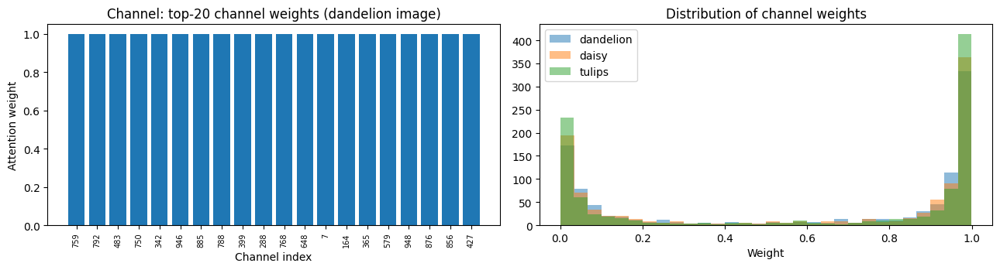

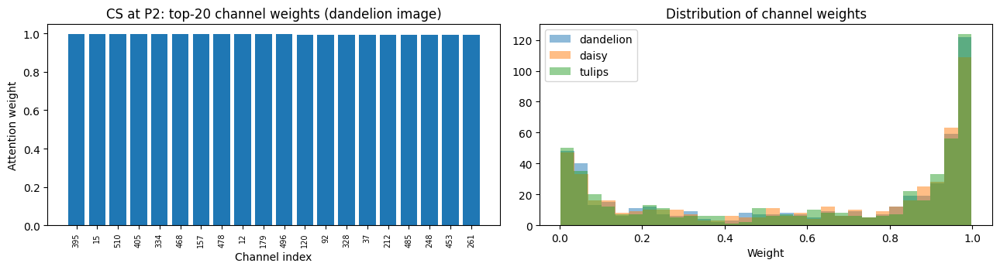

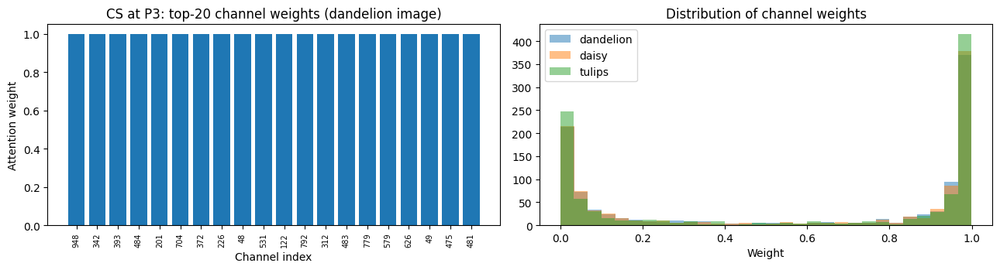

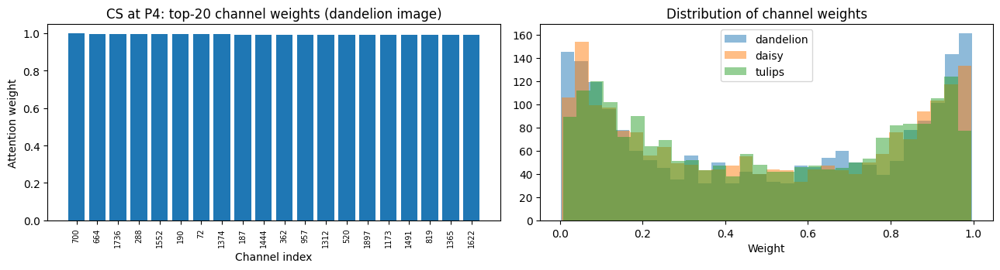

In [ ]:
import itertools
K_TOP = 20
CH_MODELS = [("Channel", "P3"), ("CS at P2", "P2"), ("CS at P3", "P3"), ("CS at P4", "P4")]
ch_rows, ch_weights = [], {}
for name, pos in CH_MODELS:
    if name not in models:
        continue
    ln = find_layer_name(models[name], pos, "fc2")
    probe = tf.keras.Model(models[name].inputs, models[name].get_layer(ln).output)
    W = np.concatenate([probe(prep(i), training=False).numpy().reshape(1, -1) for i in VIS_IDX], axis=0)
    ch_weights[name] = W                                   # shape (n_images, C)
    top10 = [set(np.argsort(-w)[:10]) for w in W]
    jac = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(top10, 2)])
    ch_rows.append({"Model": name, "Position": pos, "Channels": W.shape[1], "Mean weight": W.mean(),
                    "Std of weights": W.std(), "Fraction > 0.5": (W > 0.5).mean(),
                    "Top-10 channel overlap between images (Jaccard)": jac})
display(pd.DataFrame(ch_rows).round(4))

for name, W in ch_weights.items():
    order = np.argsort(-W[0])[:K_TOP]
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    axes[0].bar(range(K_TOP), W[0][order])
    axes[0].set_xticks(range(K_TOP), order, rotation=90, fontsize=7)
    axes[0].set_title(f"{name}: top-{K_TOP} channel weights ({class_names[y_test[VIS_IDX[0]]]} image)")
    axes[0].set_xlabel("Channel index"); axes[0].set_ylabel("Attention weight")
    for i, w in enumerate(W):
        axes[1].hist(w, bins=30, alpha=0.5, label=class_names[y_test[VIS_IDX[i]]])
    axes[1].set_title("Distribution of channel weights"); axes[1].set_xlabel("Weight"); axes[1].legend()
    plt.tight_layout(); plt.show()

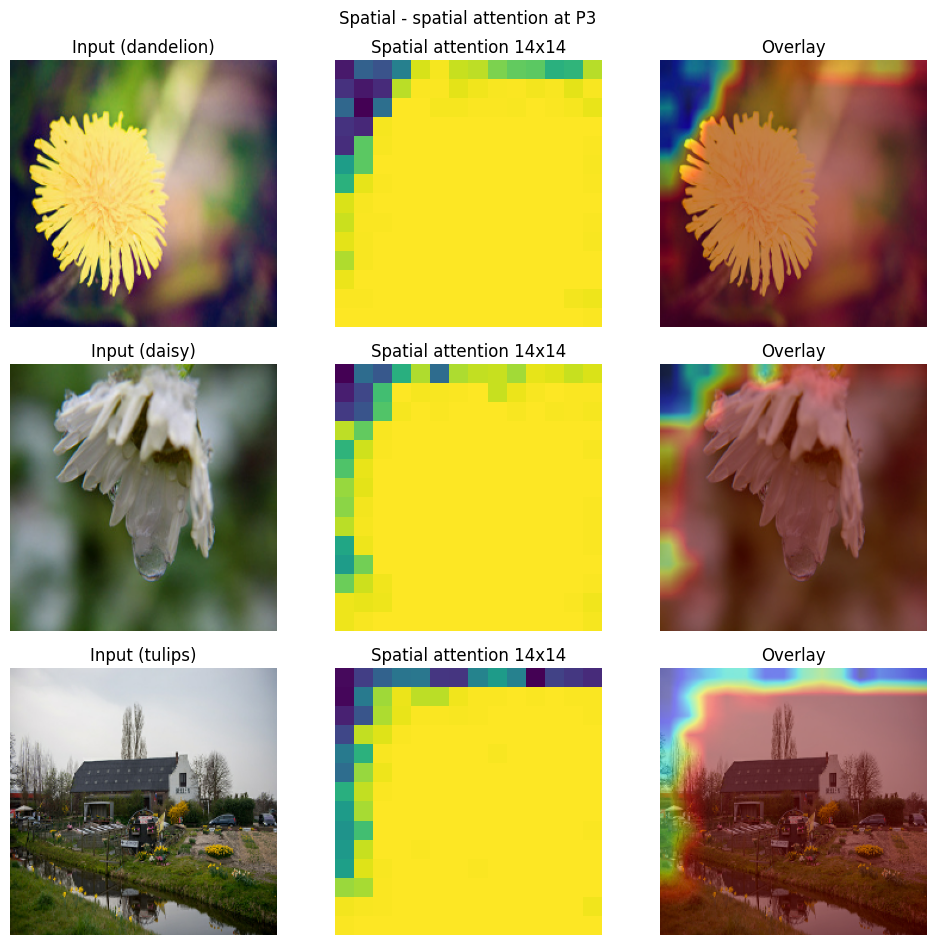

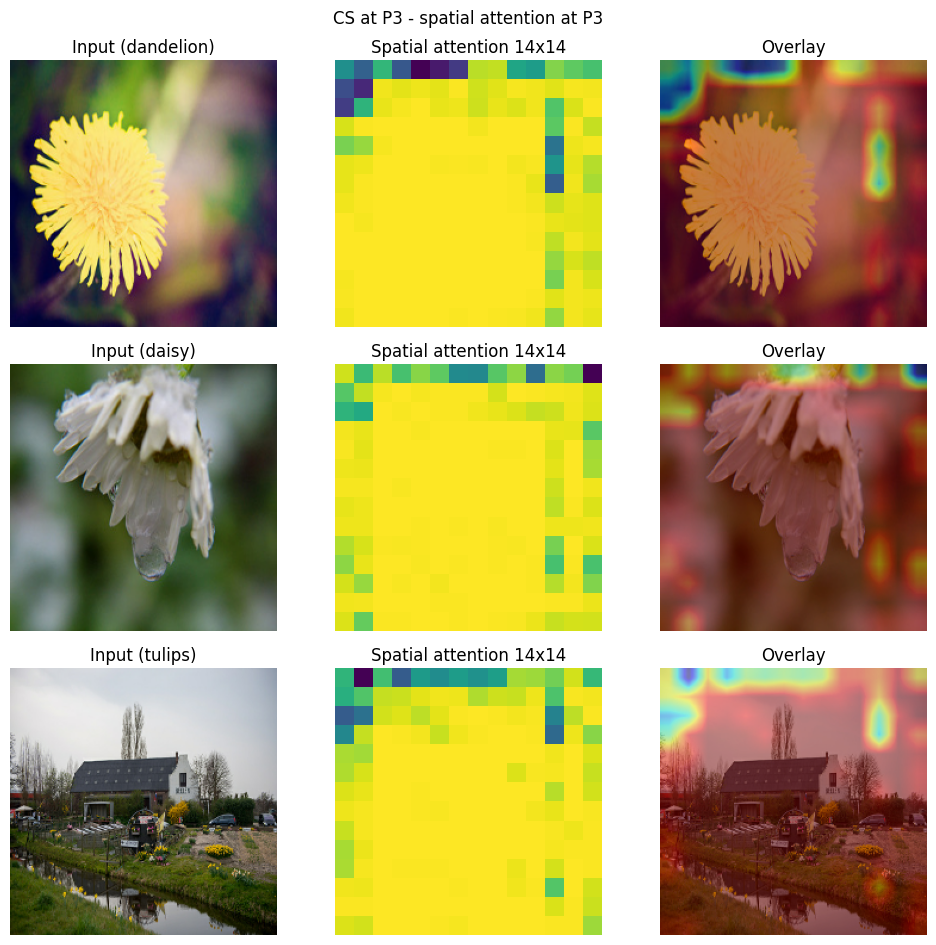

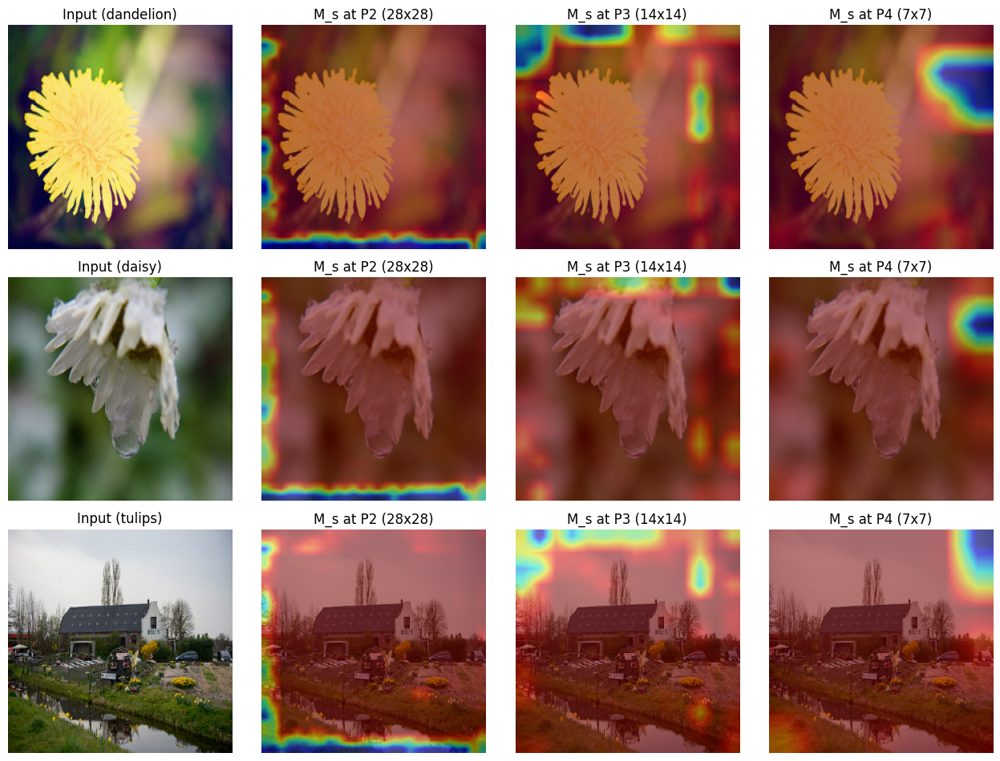

In [ ]:
def show_spatial_maps(model_name, pos):
    model = models[model_name]
    ln = find_spatial_layer(model, pos)
    probe = tf.keras.Model(model.inputs, model.get_layer(ln).output)
    fig, axes = plt.subplots(len(VIS_IDX), 3, figsize=(10, 3.2 * len(VIS_IDX)), squeeze=False)
    for r, idx in enumerate(VIS_IDX):
        m = probe(prep(idx), training=False).numpy()[0, :, :, 0]
        raw = x_test[idx].astype("uint8")
        axes[r, 0].imshow(raw); axes[r, 0].set_title(f"Input ({class_names[y_test[idx]]})")
        axes[r, 1].imshow(m, cmap="viridis"); axes[r, 1].set_title(f"Spatial attention {m.shape[0]}x{m.shape[1]}")
        axes[r, 2].imshow(raw); axes[r, 2].imshow(to_img(m), cmap="jet", alpha=0.45); axes[r, 2].set_title("Overlay")
    for ax in axes.ravel(): ax.axis("off")
    fig.suptitle(f"{model_name} - spatial attention at {pos}"); plt.tight_layout(); plt.show()

for name, pos in [("Spatial", "P3"), ("CS at P3", "P3")]:
    if name in models:
        show_spatial_maps(name, pos)

POS_MODELS = [("CS at P2", "P2"), ("CS at P3", "P3"), ("CS at P4", "P4")]
POS_MODELS = [(n, p) for n, p in POS_MODELS if n in models]
probes = {p: tf.keras.Model(models[n].inputs, models[n].get_layer(find_spatial_layer(models[n], p)).output)
          for n, p in POS_MODELS}
fig, axes = plt.subplots(len(VIS_IDX), 1 + len(POS_MODELS), figsize=(3.2 * (1 + len(POS_MODELS)), 3.2 * len(VIS_IDX)),
                         squeeze=False)
for r, idx in enumerate(VIS_IDX):
    raw = x_test[idx].astype("uint8")
    axes[r, 0].imshow(raw); axes[r, 0].set_title(f"Input ({class_names[y_test[idx]]})")
    for c, (n, p) in enumerate(POS_MODELS, start=1):
        m = probes[p](prep(idx), training=False).numpy()[0, :, :, 0]
        axes[r, c].imshow(raw); axes[r, c].imshow(to_img(m), cmap="jet", alpha=0.5)
        axes[r, c].set_title(f"M_s at {p} ({m.shape[0]}x{m.shape[1]})")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

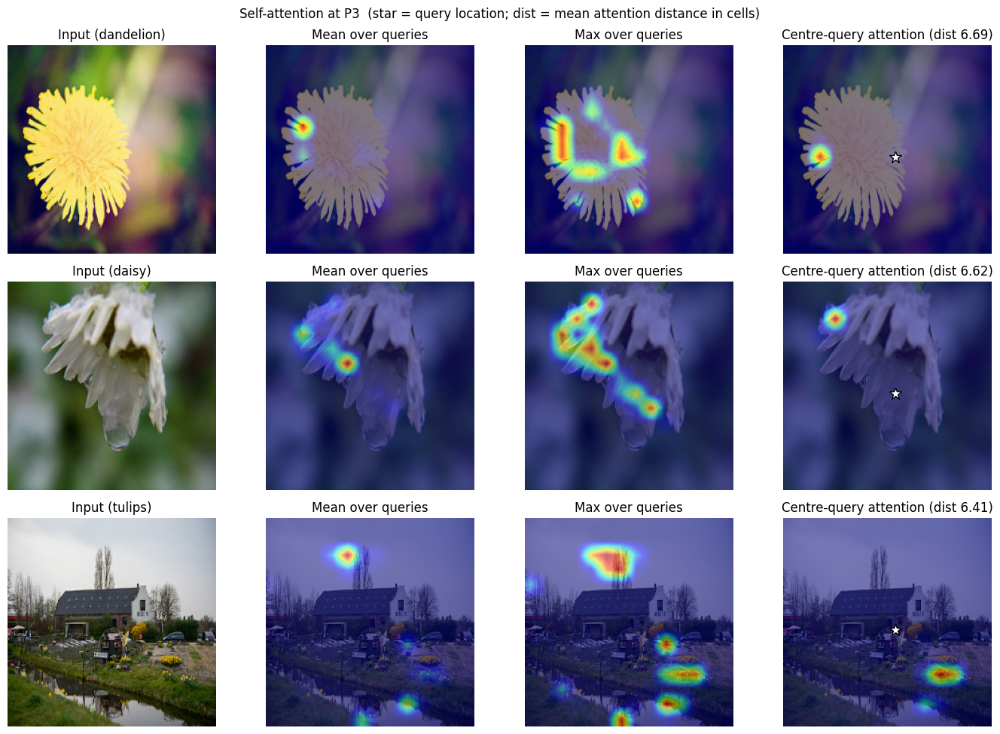

In [ ]:
if "Self-Attention" in models:
    sa_model = models["Self-Attention"]
    ln = find_layer_name(sa_model, "P3", "_weights")          # softmax attention matrix (N x N)
    probe = tf.keras.Model(sa_model.inputs, sa_model.get_layer(ln).output)
    fig, axes = plt.subplots(len(VIS_IDX), 4, figsize=(14, 3.3 * len(VIS_IDX)), squeeze=False)
    for r, idx in enumerate(VIS_IDX):
        A = probe(prep(idx), training=False).numpy()[0]       # (N, N): row = query, column = key
        n_tok = A.shape[0]; h = w = int(round(n_tok ** 0.5))
        q = (h // 2) * w + (w // 2)                           # centre query position
        yy, xx = np.divmod(np.arange(n_tok), w)
        dist = np.sqrt((yy[:, None] - yy[None, :]) ** 2 + (xx[:, None] - xx[None, :]) ** 2)
        mean_dist = float((A * dist).sum(1).mean())           # average attention distance (feature-map cells)
        raw = x_test[idx].astype("uint8")
        axes[r, 0].imshow(raw); axes[r, 0].set_title(f"Input ({class_names[y_test[idx]]})")
        for c, (m, t) in enumerate([(A.mean(0), "Mean over queries"), (A.max(0), "Max over queries"),
                                    (A[q], "Centre-query attention")], start=1):
            axes[r, c].imshow(raw); axes[r, c].imshow(to_img(m.reshape(h, w)), cmap="jet", alpha=0.5)
            axes[r, c].set_title(t if c < 3 else f"{t} (dist {mean_dist:.2f})")
        axes[r, 3].plot((q % w) * IMG_SIZE / w + IMG_SIZE / (2 * w), (q // w) * IMG_SIZE / h + IMG_SIZE / (2 * h),
                        "w*", markersize=12, markeredgecolor="k")
    for ax in axes.ravel(): ax.axis("off")
    fig.suptitle("Self-attention at P3  (star = query location; dist = mean attention distance in cells)")
    plt.tight_layout(); plt.show()

In [ ]:
with open("selected_hyperparameters.json", "w") as f:
    json.dump({"seed": SEED, "best_learning_rate": BEST_LR,
               "best_dropout": BEST_DROPOUT, "batch_size": BATCH_SIZE,
               "epochs_tuning": EPOCHS_TUNING, "epochs_attention": EPOCHS_ATTENTION,
               "image_size": IMG_SIZE, "split": "70/15/15"}, f, indent=2)

for name, model in models.items():
    safe = name.replace("→", "_").replace(" ", "_").replace("/", "_")
    try:
        model.save(f"{safe}.keras")
    except Exception as e:
        print("Could not save", name, e)

print("Saved attention_results.csv, selected_hyperparameters.json, and model checkpoints where possible.")

Saved attention_results.csv, selected_hyperparameters.json, and model checkpoints where possible.
